# Analysis of uoe5 pipeline run
Reran antibody panel 1 with new updates within the pipeline, resutling in run uoe5.

Major pipeline changes include more quality control mesasures focused on organelle channels (lysosome, endosome, and mitochondria) - I added the contrast check that we run for the nuclues channel to script 3 to check each channel before segmentation is preformed. The organelle channels are generally more dim than the nuclues channel, so the threshold for QC is quite a bit lower than that of the nucleus channel.

The goals here are to preform the prior PCA analyses (plus additional analysis on the genotype level, manual focused analsysis, and structure level analysis) and assess whether we reduced the number of poor quality images that make it to this analysis stage. 

In [1]:
import pathlib as Path
import pandas as pd
import os

import glob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Metadata validation
Alena aggregated all of the cell culture group's metadata information: iNDI_Plate_ID, Well_ID, Genotype_Name, JAX_ID, Batch_Info, Cell_Line_Info\
We later queried JAX_ID on the Jackson labs webpage (see JAX_iPSC_Catalog.tsv) to aquire all clean annotation which was merged into the metadata sheet - colnames: JAX_Code, Gene, Variant, Genotype, Gene_Var_Type

In [2]:
all_automated_plates_combined_fn = "/data/CARDPB2/iNDI/Production/metadata/all_automated_plates_combined.csv"
all_automated_plates_combined = pd.read_csv(all_automated_plates_combined_fn)

print(all_automated_plates_combined.head())

  iNDI_Plate_ID Well_ID      Genotype_Name       JAX_ID Batch_Info  \
0    INDI00026D     A01  HNRNPA1 D262N HOM  JIPSC001038        NaN   
1    INDI00026D     A02  HNRNPA1 D262N HOM  JIPSC001038        NaN   
2    INDI00026D     A03  HNRNPA1 D262N REV  JIPSC001042        NaN   
3    INDI00026D     A04  HNRNPA1 D262N HOM  JIPSC001038        NaN   
4    INDI00026D     A05      PFN1 C71G HET  JIPSC001034        NaN   

      JAX_Code     Gene Variant Genotype          Gene_Var_Type  \
0  JIPSC001038  HNRNPA1   D262N  SNV/SNV  HNRNPA1_D262N_SNV/SNV   
1  JIPSC001038  HNRNPA1   D262N  SNV/SNV  HNRNPA1_D262N_SNV/SNV   
2  JIPSC001042  HNRNPA1   D262N   REV/WT   HNRNPA1_D262N_REV/WT   
3  JIPSC001038  HNRNPA1   D262N  SNV/SNV  HNRNPA1_D262N_SNV/SNV   
4  JIPSC001034     PFN1    C71G   SNV/WT       PFN1_C71G_SNV/WT   

                                      Cell_Line_Info  
0  JAX_ID_JIPSC001038\nHNRNPA1 D262N HOM\nLow cou...  
1  JAX_ID_JIPSC001038\nHNRNPA1 D262N HOM\nLow cou...  
2  JAX_ID_J

In [3]:
files = glob.glob("/data/kelpschdj/iNDI/Production/outputs/run_20260901_155524_uoe5/organelle_features/*_organelle_features_*.parquet")

parts = []
for f in files:
    part = pd.read_parquet(f)
    parts.append(part)
    print(f"{os.path.basename(f)}: {len(part)} rows")

df = pd.concat(parts, ignore_index=True)

print(f"\nLoaded {len(files)} files, {len(df)} total rows")
print(df.head())
print(df.columns.tolist())

028ebee9-afaf-4ff8-b435-af11714285dc_organelle_features__20260902_114905.parquet: 116923 rows
07fc5da6-9d7d-4c97-858b-4b76df1859a5_organelle_features__20260902_114905.parquet: 115713 rows
2350e82d-40dd-4bb4-93de-44edec0d1718_organelle_features__20260902_114905.parquet: 138260 rows
2b1c31ad-579d-4ea6-a782-251ea083ed6a_organelle_features__20260902_114905.parquet: 206382 rows
2da14033-ab86-4f33-b4f7-ef375c80ce62_organelle_features__20260902_114905.parquet: 166866 rows
32d75d22-bd17-4629-8257-a4056e3ffcee_organelle_features__20260902_114905.parquet: 107005 rows
4405a3b2-6b88-49b1-91f3-992e09ccbd16_organelle_features__20260902_114905.parquet: 131590 rows
51cf625a-9422-406f-aa9e-a9f1238d1b96_organelle_features__20260902_114905.parquet: 177582 rows
72c0a713-b5d5-4cd4-a826-c556368ed1d1_organelle_features__20260902_114905.parquet: 100645 rows
7e03b502-ad64-4090-a9e2-fc4c3ecdae11_organelle_features__20260902_114905.parquet: 169399 rows
934f6de5-f58b-4a1e-b225-ac6414500bb7_organelle_features__202

In [4]:
## pull in metadata
plate_id_fn = "/data/CARDPB2/iNDI/Production/metadata/indi_plateID_to_folderID.csv"
plate_id = pd.read_csv(plate_id_fn)
print(plate_id.head())

automated_plates_fn = "/data/CARDPB2/iNDI/Production/metadata/all_automated_plates_combined.csv"
manual_plates_fn = "/data/CARDPB2/iNDI/Production/metadata/all_manual_plates_combined.csv"

automated_plate_md = pd.read_csv(automated_plates_fn)
manual_plates_md = pd.read_csv(manual_plates_fn)

parts = manual_plates_md["Genotype_Name"].str.split(" ", n=2, expand=True)
is_triple = manual_plates_md["Genotype_Name"].str.split().str.len() == 3
is_parental = manual_plates_md["Genotype_Name"].str.strip() == "Parental"

manual_plates_md["Gene"] = np.select(
    [is_parental, is_triple],
    ["KOLF2.1J", parts[0]],
    default=np.nan,
)
manual_plates_md["Variant"] = np.select(
    [is_parental, is_triple],
    ["NA", parts[1]],
    default=np.nan,
)
manual_plates_md["Common_genotype"] = np.select(
    [is_parental, is_triple],
    ["wild-type", parts[2]],
    default=np.nan,
)

print(automated_plate_md.head())
print(manual_plates_md.head())

auto_cols = automated_plate_md.columns.tolist()
man_cols = manual_plates_md.columns.tolist()

print("Cols only in automated:", [c for c in auto_cols if c not in man_cols])
print("Cols only in manual:   ", [c for c in man_cols if c not in auto_cols])

# label each source before combining
automated_plate_md = automated_plate_md.copy()
manual_plates_md = manual_plates_md.copy()
automated_plate_md["prep_method"] = "automated"
manual_plates_md["prep_method"] = "manual"

# make sure the manual df uses the same column order
manual_plates_md = manual_plates_md.reindex(columns=automated_plate_md.columns)

# append rows
all_plates_md = pd.concat([automated_plate_md, manual_plates_md], ignore_index=True)

print(all_plates_md.columns.tolist())
print(all_plates_md.shape)
print(all_plates_md["prep_method"].value_counts())
print(df.columns.tolist())

print("df Measurement_ID sample:", df["Measurement_ID"].head(3).tolist())
print("plate_id Folder_ID sample:", plate_id["Folder_ID"].head(3).tolist())
print("df dtype:", df["Measurement_ID"].dtype, "| plate_id dtype:", plate_id["Folder_ID"].dtype)

# keep only the mapping columns you need
plate_id_map = plate_id[["Folder_ID", "iNDI_Plate_ID", "Layout"]].drop_duplicates("Folder_ID")

# optional: remove columns in df that would collide
df = df.drop(columns=["Folder_ID", "iNDI_Plate_ID", "Layout"], errors="ignore")

print("Folder_ID unique?", plate_id_map["Folder_ID"].is_unique)
print("Folder_IDs in plate_id:", plate_id_map["Folder_ID"].nunique())

df_ids = set(df["Measurement_ID"].unique())
map_ids = set(plate_id_map["Folder_ID"].unique())
print(f"df experiments: {len(df_ids)} | matched in map: {len(df_ids & map_ids)} | unmatched: {len(df_ids - map_ids)}")

df = df.merge(
    plate_id_map,
    left_on="Measurement_ID",
    right_on="Folder_ID",
    how="left",
    validate="many_to_one",
    suffixes=("", "")  # no overlap now, so no _x/_y
)

print(f"After merge: {len(df)} rows")
print(df.columns.tolist())

# build Well_ID
import string
df["Well_ID"] = df.apply(
    lambda r: f"{string.ascii_uppercase[int(r['Row'])-1]}{int(r['Column']):02d}",
    axis=1,
)

# match-rate on the FULL composite key
df_keys = set(zip(df["iNDI_Plate_ID"], df["Well_ID"]))
md_keys = set(zip(all_plates_md["iNDI_Plate_ID"], all_plates_md["Well_ID"]))
print(f"df keys: {len(df_keys)} | matched: {len(df_keys & md_keys)} | unmatched: {len(df_keys - md_keys)}")

# metadata composite key unique?
print("md plate+well unique?",
      not all_plates_md.duplicated(["iNDI_Plate_ID", "Well_ID"]).any())

df = df.merge(
    all_plates_md,
    on=["iNDI_Plate_ID", "Well_ID"],
    how="left",
    validate="many_to_one",
)
print(f"After merge: {len(df)} rows")   # should be unchanged
print(df.columns.tolist())

  iNDI_Plate_ID    Layout                             Folder_ID
0    INDI00002D  Plate002  2b1c31ad-579d-4ea6-a782-251ea083ed6a
1    INDI00007D  Plate007  d7e04b5c-a253-42ff-859f-2af0e6047a00
2    INDI00011D  Plate011  f8062781-891b-4688-a59e-fccbf48325cf
3    INDI00015D  Plate015  caef83c7-6b44-4b64-b8ec-e8d84ca6759d
4    INDI00019D  Plate019  c8f2dbbe-6632-4063-ab68-0b4fa37909af
  iNDI_Plate_ID Well_ID      Genotype_Name       JAX_ID Batch_Info  \
0    INDI00026D     A01  HNRNPA1 D262N HOM  JIPSC001038        NaN   
1    INDI00026D     A02  HNRNPA1 D262N HOM  JIPSC001038        NaN   
2    INDI00026D     A03  HNRNPA1 D262N REV  JIPSC001042        NaN   
3    INDI00026D     A04  HNRNPA1 D262N HOM  JIPSC001038        NaN   
4    INDI00026D     A05      PFN1 C71G HET  JIPSC001034        NaN   

      JAX_Code     Gene Variant Genotype          Gene_Var_Type  \
0  JIPSC001038  HNRNPA1   D262N  SNV/SNV  HNRNPA1_D262N_SNV/SNV   
1  JIPSC001038  HNRNPA1   D262N  SNV/SNV  HNRNPA1_D262N_SNV/S

Folder_ID unique? True
Folder_IDs in plate_id: 35
df experiments: 21 | matched in map: 21 | unmatched: 0
After merge: 2963186 rows
['Measurement_ID', 'subdirectory', 'Row', 'Column', 'Frame', 'Plane', 'Time', 'DAPI_filename', 'channel_filename', 'Structure', 'Stain', 'Nucleus_ID', 'frame_std', 'contrast_check', 'area_px', 'organelle_count', 'average_organelle_area', 'roi_occupancy', 'max_f_intensity', 'sum_f_intensity', 'mean_f_intensity', 'median_f_intensity', 'CoefOfVar_intensity', 'area_mean', 'area_median', 'area_std', 'area_p10', 'area_p90', 'perimeter_mean', 'perimeter_median', 'perimeter_std', 'perimeter_p10', 'perimeter_p90', 'eccentricity_mean', 'eccentricity_median', 'eccentricity_std', 'eccentricity_p10', 'eccentricity_p90', 'solidity_mean', 'solidity_median', 'solidity_std', 'solidity_p10', 'solidity_p90', 'extent_mean', 'extent_median', 'extent_std', 'extent_p10', 'extent_p90', 'axis_major_length_mean', 'axis_major_length_median', 'axis_major_length_std', 'axis_major_lengt

In [5]:
for plate, grp in df.groupby('iNDI_Plate_ID'):
    print(f"\n{plate}")
    print(grp.groupby('Gene_Var_Type')['Well_ID'].nunique())


INDI00002D
Gene_Var_Type
FUS_R495X_REV/WT     48
FUS_R495X_SNV/SNV    48
FUS_R495X_SNV/WT     48
KOLF2.1J             96
VCP_R159H_REV/WT     48
VCP_R159H_SNV/SNV    48
VCP_R159H_SNV/WT     48
Name: Well_ID, dtype: int64

INDI00007D
Gene_Var_Type
KOLF2.1J                96
TARDBP_M337V_REV/WT     48
TARDBP_M337V_SNV/WT     48
TARDBP_Q331K_SNV/SNV    47
TIA1_P351L_REV/WT       48
TIA1_P351L_SNV/SNV      48
Name: Well_ID, dtype: int64

INDI00011D
Gene_Var_Type
FUS_R216C_SNV/SNV      47
KOLF2.1J               96
PSEN2_N141I_REV/WT     47
PSEN2_N141I_SNV/SNV    48
TBK1_E696K_REV/WT       3
TBK1_E696K_SNV/SNV      4
TBK1_E696K_SNV/WT       2
Name: Well_ID, dtype: int64

INDI00015D
Gene_Var_Type
APP_A673T_REV/WT      48
APP_A673T_SNV/WT      48
APP_E693G_SNV/SNV     48
APP_E693G_SNV/WT      48
APP_V717I_SNV/SNV     48
KOLF2.1J              48
PSEN1_E276A_SNV/WT    48
Name: Well_ID, dtype: int64

INDI00019D
Gene_Var_Type
APP_E693G_REV/WT       41
FUS_R216C_REV/WT       47
FUS_R216C_SNV/WT   

In [6]:
## add new analysis to check number of channels per nucleus is 4 (including nuclear channel) for all nuclei in the dataset - If a nucleus has less than 4 channels remove it from analysis
counts = (
    df.groupby(["DAPI_filename", "Nucleus_ID"])["Structure"]
        .nunique()
)

keep_keys = counts[counts == 3].index


filtered = df.set_index(["DAPI_filename", "Nucleus_ID"]).loc[keep_keys].reset_index()
print(f"Filtered dataset: {len(filtered)} rows (from {len(df)} original rows)")

Filtered dataset: 2959102 rows (from 2963186 original rows)


Reduced by ~ 4500 ROIs

In [7]:
df = filtered  # replace the original df with the filtered one for further analysis

## Filter nucleus data

In [8]:
nuc_files = glob.glob("/data/kelpschdj/iNDI/Production/outputs/run_20260901_155524_uoe5/nuclei_filtered/*_image_qc.parquet")

parts = []
for f in nuc_files:
    part = pd.read_parquet(f)
    parts.append(part)
    print(f"{os.path.basename(f)}: {len(part)} rows")

nuc_df = pd.concat(parts, ignore_index=True)

print(f"\nLoaded {len(nuc_files)} files, {len(nuc_df)} total rows")
print(nuc_df.head())
print(nuc_df.columns.tolist())

ValueError: No objects to concatenate

In [ ]:
nuc_feature_files = glob.glob("/data/kelpschdj/iNDI/Production/outputs/run_20260901_155524_uoe5/nuclei_features/*_nuclei_features.parquet")

parts = []
for f in nuc_feature_files:
    part = pd.read_parquet(f)
    parts.append(part)
    print(f"{os.path.basename(f)}: {len(part)} rows")

nuc_features_df = pd.concat(parts, ignore_index=True)

print(f"\nLoaded {len(nuc_feature_files)} files, {len(nuc_features_df)} total rows")
print(nuc_features_df.head())
print(nuc_features_df.columns.tolist())

028ebee9-afaf-4ff8-b435-af11714285dc_nuclei_features.parquet: 87928 rows
07fc5da6-9d7d-4c97-858b-4b76df1859a5_nuclei_features.parquet: 81886 rows
2350e82d-40dd-4bb4-93de-44edec0d1718_nuclei_features.parquet: 98782 rows
2b1c31ad-579d-4ea6-a782-251ea083ed6a_nuclei_features.parquet: 124127 rows
2da14033-ab86-4f33-b4f7-ef375c80ce62_nuclei_features.parquet: 109822 rows
32d75d22-bd17-4629-8257-a4056e3ffcee_nuclei_features.parquet: 68940 rows
4405a3b2-6b88-49b1-91f3-992e09ccbd16_nuclei_features.parquet: 90673 rows
51cf625a-9422-406f-aa9e-a9f1238d1b96_nuclei_features.parquet: 125952 rows
72c0a713-b5d5-4cd4-a826-c556368ed1d1_nuclei_features.parquet: 70820 rows
7e03b502-ad64-4090-a9e2-fc4c3ecdae11_nuclei_features.parquet: 112023 rows
934f6de5-f58b-4a1e-b225-ac6414500bb7_nuclei_features.parquet: 110118 rows
9697941f-11d4-43bb-8f50-d424c4e05c29_nuclei_features.parquet: 109010 rows
b96883e9-18b4-4f0d-ba6e-0ddd08c5413f_nuclei_features.parquet: 102498 rows
c170959e-633a-458c-8542-2aa619c0d7f8_nuclei_

In [ ]:
unique_features_df = nuc_features_df[["Measurement_ID", "filename"]].drop_duplicates()
print(len(unique_features_df))

unique_nuc_df = nuc_df[["Measurement_ID", "filename"]].drop_duplicates()
print(len(unique_nuc_df))

unique_nuc_df_filtered = (
    nuc_df[nuc_df["filter_status"] == "pass"]
    [["Measurement_ID", "filename"]]
    .drop_duplicates()
)
print(len(unique_nuc_df_filtered))

204887
204887
0


In [ ]:
df_organelle_key = df[["Measurement_ID", "DAPI_filename", "Nucleus_ID"]].drop_duplicates()
print(len(df_organelle_key))

filtered_nuc = nuc_features_df.merge(
    df_organelle_key.rename(columns={"DAPI_filename": "filename", "Nucleus_ID": "label"}),
    on=["Measurement_ID", "filename", "label"],
    how="inner",
)

print(len(nuc_features_df))
print(len(filtered_nuc[["Measurement_ID", "filename", "label"]].drop_duplicates()))
print(len(df))

# save the new filtered list and send to Alena
#filtered_nuc.to_parquet("uoe5_allqc_nuclei.parquet", index=False)

990726
1960759
990726
2959102


## Apply subjective filters from Marianita

In [ ]:
# randomization_batch
randomization_batch_fn = "/data/CARDPB2/iNDI/Production/metadata/AbPanel1/batches.csv"
randomization_batch = pd.read_csv(randomization_batch_fn)
randomization_batch = randomization_batch[randomization_batch["AbPanel"] == 1].copy()

print("batches columns:", randomization_batch.columns.tolist())
print(randomization_batch.head())
print("\ndf columns:", df.columns.tolist())
print(df.head())

merged = df.merge(
    randomization_batch[["iNDI_Plate_ID", "Batch"]],
    on="iNDI_Plate_ID",
    how="left",
    validate="many_to_one",
)

batches columns: ['iNDI_Plate_ID', 'AbPanel', 'Batch']
  iNDI_Plate_ID  AbPanel  Batch
0    INDI00002D        1      1
2    INDI00007D        1      1
4    INDI00011D        1      1
5    INDI00015D        1      1
7    INDI00019D        1      2

df columns: ['DAPI_filename', 'Nucleus_ID', 'Measurement_ID', 'subdirectory', 'Row', 'Column', 'Frame', 'Plane', 'Time', 'channel_filename', 'Structure', 'Stain', 'frame_std', 'contrast_check', 'area_px', 'organelle_count', 'average_organelle_area', 'roi_occupancy', 'max_f_intensity', 'sum_f_intensity', 'mean_f_intensity', 'median_f_intensity', 'CoefOfVar_intensity', 'area_mean', 'area_median', 'area_std', 'area_p10', 'area_p90', 'perimeter_mean', 'perimeter_median', 'perimeter_std', 'perimeter_p10', 'perimeter_p90', 'eccentricity_mean', 'eccentricity_median', 'eccentricity_std', 'eccentricity_p10', 'eccentricity_p90', 'solidity_mean', 'solidity_median', 'solidity_std', 'solidity_p10', 'solidity_p90', 'extent_mean', 'extent_median', 'extent_s

In [ ]:
# MS_filter 
MS_filter_fn = "/data/CARDPB2/iNDI/Production/metadata/AbPanel1/marianita_excluded_genotypes_by_plate.csv"
MS_filter = pd.read_csv(MS_filter_fn)
print("MS_filter columns:", MS_filter.columns.tolist())
print(MS_filter.head())

def norm_geno(s):
    return (
        s.astype(str)
         .str.strip()
         .str.replace("_", " ", regex=False)   # underscores -> spaces
         .str.replace(r"\s+", " ", regex=True)  # collapse repeats
         .str.upper()                            # case-insensitive
    )

remove_pairs = set(zip(
    MS_filter["iNDI_Plate_ID"].astype(str).str.strip(),
    norm_geno(MS_filter["Genotype_Name"]),
))

key = list(zip(
    merged["iNDI_Plate_ID"].astype(str).str.strip(),
    norm_geno(merged["Genotype_Name"]),
))
mask = pd.Series(key, index=merged.index).isin(remove_pairs)

filtered = merged[~mask].copy()
print(f"removed {mask.sum()} rows; {len(filtered)} remain")

# confirm the normalization actually bridged the two formats
missing = remove_pairs - set(key)
if missing:
    print(f"note: {len(missing)} pair(s) still unmatched after normalization:")
    for p in sorted(missing):
        print("  ", p)

MS_filter columns: ['iNDI_Plate_ID', 'Genotype_Name']
  iNDI_Plate_ID    Genotype_Name
0    INDI00007D   TIA1_P351L_HET
1    INDI00008D   TIA1_P351L_HET
2    INDI00011D  PSEN2_N141I_REV
3    INDI00011D   TBK1_E696K_HET
4    INDI00011D   TBK1_E696K_HOM


removed 22895 rows; 2936207 remain
note: 27 pair(s) still unmatched after normalization:
   ('INDI00007D', 'TIA1 P351L HET')
   ('INDI00008D', 'TIA1 P351L HET')
   ('INDI00016D', 'PSEN1 E276A HET')
   ('INDI00020D', 'APP E693G REV')
   ('INDI00020D', 'PSEN1 E276A HOM')
   ('INDI00020D', 'PSEN2 N141I HET')
   ('INDI00023D', 'SNCB P123H REV')
   ('INDI00024D', 'SNCB P123H HET')
   ('INDI00024D', 'SNCB P123H HOM')
   ('INDI00024D', 'SNCB P123H REV')
   ('INDI00026D', 'HNRNPA1 D262N REV')
   ('INDI00026D', 'PFN1 C71G HET')
   ('INDI00028D', 'HNRNPA1 D262N HOM')
   ('INDI00028D', 'HNRNPA1 D262N REV')
   ('INDI00028D', 'PFN1 C71G HET')
   ('INDI00039D', 'SNCB P123H HET')
   ('INDI00040D', 'PSEN2 N141I HET')
   ('INDI00040D', 'SNCB P123H HET')
   ('INDI00044D', 'HNRNPA1 D262N HOM')
   ('INDI00044D', 'HNRNPA1 D262N REV')
   ('INDI00047D', 'PFN1 C71G HET')
   ('INDI00047D', 'PSEN1 E276A HET')
   ('INDI00048D', 'GRN Q125X HOM')
   ('INDI00048D', 'PFN1 C71G HET')
   ('INDI00048D', 'PSEN1 E276A HE

In [ ]:
df = filtered  # replace the original df with the filtered one for further analysis

# SUMMARY ANALYSIS

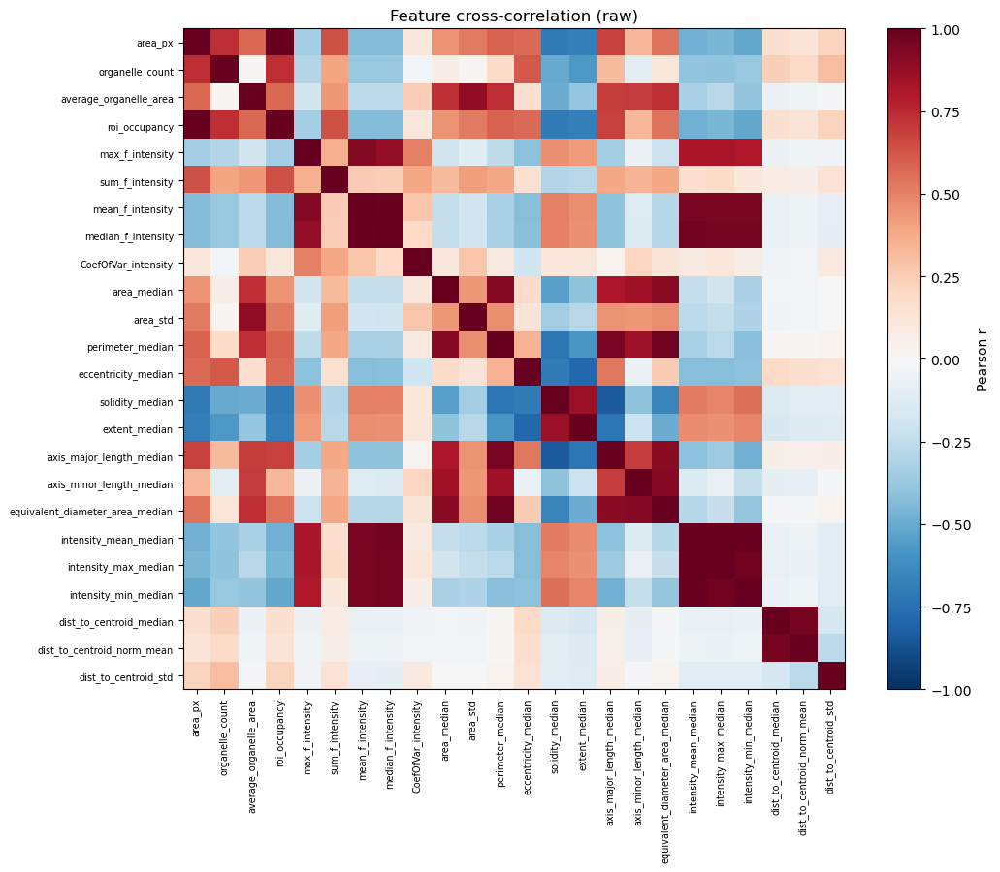

Highly correlated pairs (|r| > 0.9):
  +1.000  area_px                          roi_occupancy
  +0.993  intensity_mean_median            intensity_max_median
  +0.992  mean_f_intensity                 median_f_intensity
  +0.988  intensity_mean_median            intensity_min_median
  +0.976  perimeter_median                 equivalent_diameter_area_median
  +0.968  intensity_max_median             intensity_min_median
  +0.966  median_f_intensity               intensity_mean_median
  +0.959  median_f_intensity               intensity_max_median
  +0.958  median_f_intensity               intensity_min_median
  +0.955  dist_to_centroid_median          dist_to_centroid_norm_mean
  +0.952  mean_f_intensity                 intensity_mean_median
  +0.949  perimeter_median                 axis_major_length_median
  +0.945  mean_f_intensity                 intensity_max_median
  +0.944  mean_f_intensity                 intensity_min_median
  +0.922  max_f_intensity                  mean_f_int

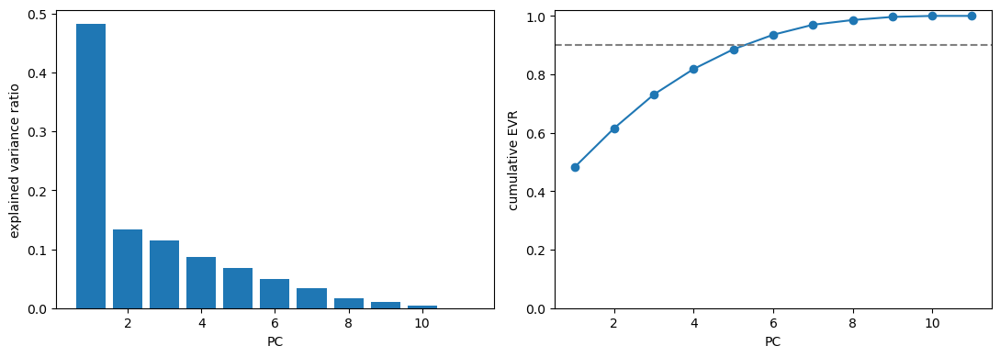

EVR: [0.482 0.134 0.115 0.087 0.067 0.05  0.034 0.016 0.011 0.003 0.   ]
cumulative: [0.482 0.616 0.731 0.818 0.886 0.936 0.97  0.986 0.997 1.    1.   ]
                              PC1    PC2    PC3    PC4    PC5    PC6
area_px                     0.382  0.262  0.073  0.116 -0.049 -0.372
organelle_count             0.339  0.203  0.050 -0.050  0.411 -0.291
roi_occupancy               0.382  0.262  0.073  0.116 -0.049 -0.372
mean_f_intensity           -0.297  0.441  0.304 -0.334 -0.053 -0.012
CoefOfVar_intensity        -0.043  0.572  0.053  0.595 -0.261  0.414
eccentricity_median         0.345 -0.064  0.117 -0.349 -0.023  0.341
solidity_median            -0.372  0.024 -0.084  0.163  0.347 -0.202
extent_median              -0.374  0.010 -0.117  0.249  0.264 -0.290
intensity_max_median       -0.299  0.357  0.303 -0.443 -0.040 -0.122
dist_to_centroid_norm_mean  0.075 -0.148  0.684  0.234  0.545  0.284
dist_to_centroid_std        0.104  0.383 -0.546 -0.207  0.515  0.360


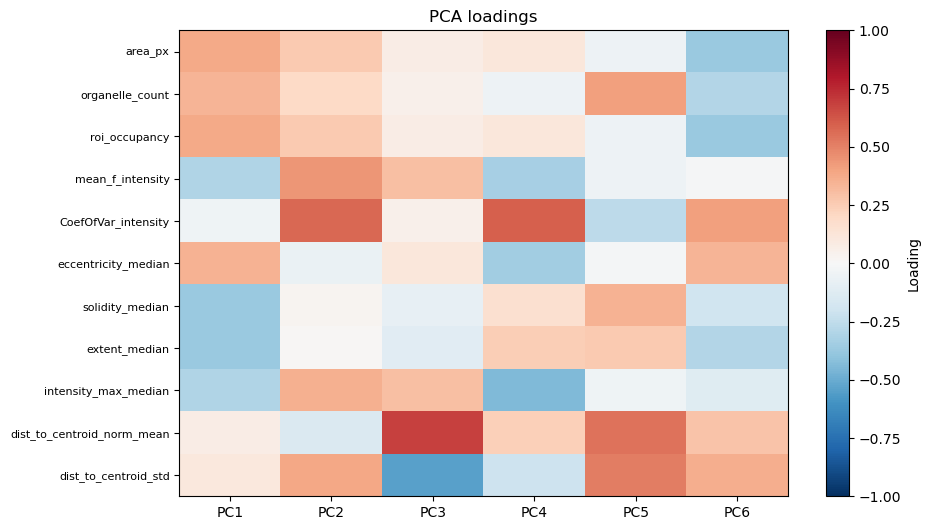

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ---------------------------------------------------------------
# STEP 0 — pick the candidate feature set (start WIDE, prune from corr)
# ---------------------------------------------------------------
# All the per-ROI numeric features worth considering. Prune AFTER seeing corr.
CANDIDATE_FEATURES = [
    # ROI-level
    "area_px", "organelle_count", "average_organelle_area", "roi_occupancy",
    # pooled-pixel intensity
    "max_f_intensity", "sum_f_intensity", "mean_f_intensity",
    "median_f_intensity", "CoefOfVar_intensity",
    # per-object shape (use median as the robust center; add _std for spread)
    "area_median", "area_std",
    "perimeter_median", "eccentricity_median", "solidity_median",
    "extent_median", "axis_major_length_median", "axis_minor_length_median",
    "equivalent_diameter_area_median",
    # per-object intensity distribution
    "intensity_mean_median", "intensity_max_median", "intensity_min_median",
    # radial organization
    "dist_to_centroid_median", "dist_to_centroid_norm_mean", "dist_to_centroid_std",
]
# keep only columns that actually exist (panel/version differences)
CANDIDATE_FEATURES = [c for c in CANDIDATE_FEATURES if c in df.columns]

# ---------------------------------------------------------------
# STEP 1 — cross-correlation (on raw, pre-scaling features)
# ---------------------------------------------------------------
X_all = df[CANDIDATE_FEATURES].replace([np.inf, -np.inf], np.nan)
corr = X_all.corr(method="pearson")

plt.figure(figsize=(11, 9))
im = plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(CANDIDATE_FEATURES)), CANDIDATE_FEATURES, rotation=90, fontsize=7)
plt.yticks(range(len(CANDIDATE_FEATURES)), CANDIDATE_FEATURES, fontsize=7)
plt.colorbar(im, label="Pearson r")
plt.title("Feature cross-correlation (raw)")
plt.tight_layout(); plt.show()

# Highly correlated pairs
hi = (corr.abs() > 0.9) & (corr.abs() < 1.0)
pairs = [
    (a, b, round(corr.loc[a, b], 3))
    for i, a in enumerate(CANDIDATE_FEATURES)
    for b in CANDIDATE_FEATURES[i + 1:]
    if hi.loc[a, b]
]
print("Highly correlated pairs (|r| > 0.9):")
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {r:+.3f}  {a:32s} {b}")

# ---------------------------------------------------------------
# STEP 2 — pruned FEATURES list
# ---------------------------------------------------------------
FEATURES = [
    "area_px", "organelle_count", "roi_occupancy",
    "mean_f_intensity", "CoefOfVar_intensity",
    "eccentricity_median", "solidity_median", "extent_median",
    "intensity_max_median",
    "dist_to_centroid_norm_mean", "dist_to_centroid_std",
]
FEATURES = [c for c in FEATURES if c in df.columns]

# drop the arithmetic identities explicitly (documented, not silent):
#   average_organelle_area = area_px / organelle_count
#   sum_f_intensity        = mean_f_intensity * area_px
#   equivalent_diameter_area_* is monotone in area_*

# ---------------------------------------------------------------
# STEP 3 — NaN/inf handling (empty ROIs -> NaN intensity/CV/dist)
# ---------------------------------------------------------------
before = len(df)
X_df = df[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = X_df.notna().all(axis=1)
df = df[keep].reset_index(drop=True)
X_df = X_df[keep].reset_index(drop=True)
print(f"Dropped {before - len(df)} rows with NaN/inf; {len(df)} remain")

# ---------------------------------------------------------------
# STEP 4 — scale + PCA
# ---------------------------------------------------------------
X = StandardScaler().fit_transform(X_df.values)
pca = PCA(n_components=len(FEATURES))
scores = pca.fit_transform(X)
for i in range(scores.shape[1]): 
    df[f"PC{i+1}"] = scores[:, i]

# ---------------------------------------------------------------
# STEP 5 — scree
# ---------------------------------------------------------------
ev = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(range(1, len(ev) + 1), ev)
ax[0].set_xlabel("PC"); ax[0].set_ylabel("explained variance ratio")
ax[1].plot(range(1, len(ev) + 1), np.cumsum(ev), marker="o")
ax[1].axhline(0.9, ls="--", c="gray"); ax[1].set_xlabel("PC")
ax[1].set_ylabel("cumulative EVR"); ax[1].set_ylim(0, 1.02)
plt.tight_layout(); plt.show()
print("EVR:", ev.round(3))
print("cumulative:", np.cumsum(ev).round(3))

# ---------------------------------------------------------------
# STEP 6 — loadings
# ---------------------------------------------------------------
n_show = min(6, len(FEATURES))
loadings = pd.DataFrame(
    pca.components_.T, index=FEATURES,
    columns=[f"PC{i+1}" for i in range(len(FEATURES))],
)
print(loadings.iloc[:, :n_show].round(3))

plt.figure(figsize=(1.6 * n_show, 0.4 * len(FEATURES) + 1))
im = plt.imshow(loadings.iloc[:, :n_show], cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
plt.xticks(range(n_show), [f"PC{i+1}" for i in range(n_show)])
plt.yticks(range(len(FEATURES)), FEATURES, fontsize=8)
plt.colorbar(im, label="Loading")
plt.title("PCA loadings")
plt.tight_layout(); plt.show()

Variance in each PC explained by Structure (η²):
  PC1: 0.794
  PC2: 0.034
  PC3: 0.048
  PC4: 0.153
  PC5: 0.097
  PC6: 0.010
  PC7: 0.184
  PC8: 0.007
  PC9: 0.023
  PC10: 0.014
  PC11: 0.067


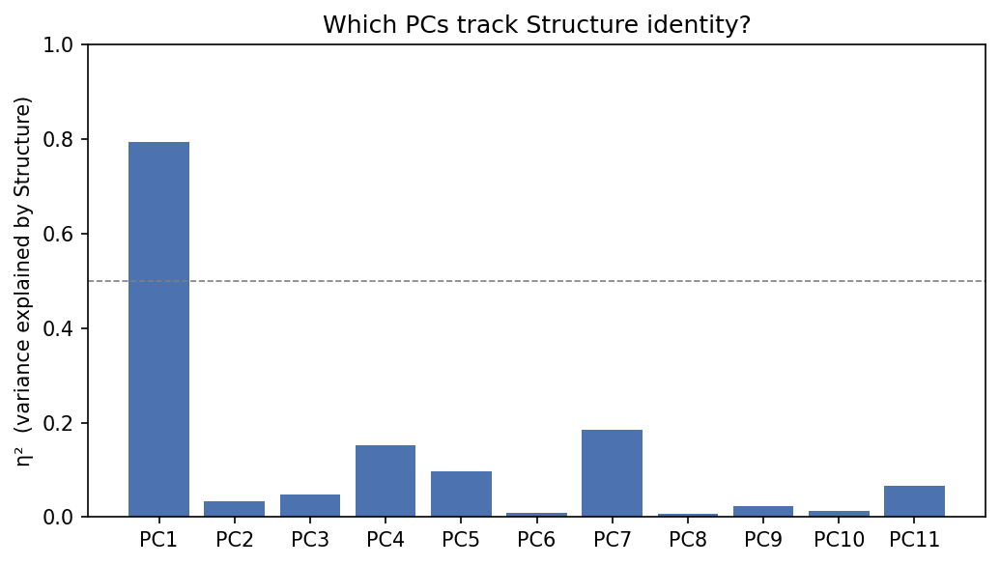

Variance in each PC explained by prep_method (η²):
  PC1: 0.011
  PC2: 0.007
  PC3: 0.002
  PC4: 0.018
  PC5: 0.002
  PC6: 0.004
  PC7: 0.006
  PC8: 0.000
  PC9: 0.006
  PC10: 0.000
  PC11: 0.001


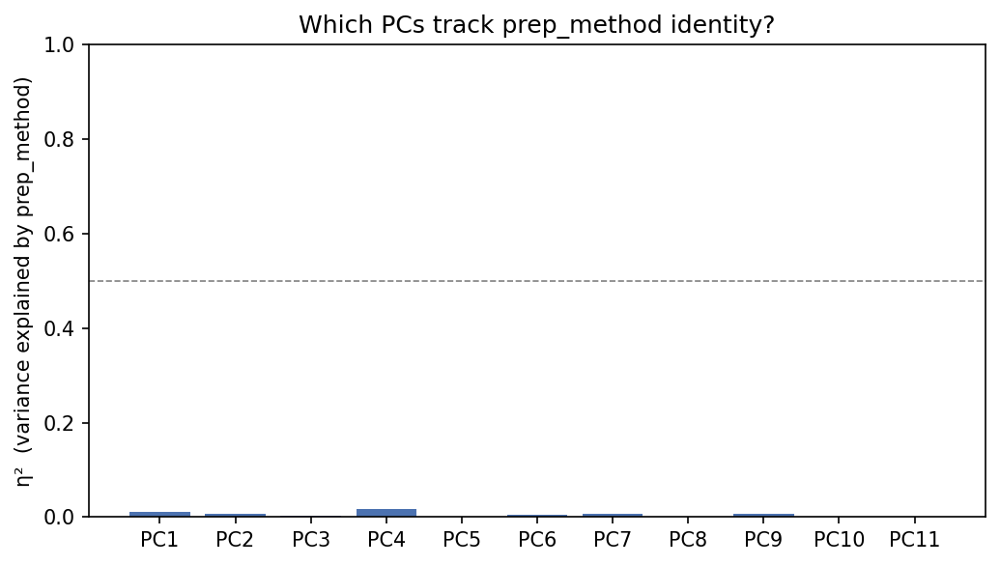

Variance in each PC explained by iNDI_Plate_ID (η²):
  PC1: 0.018
  PC2: 0.076
  PC3: 0.022
  PC4: 0.037
  PC5: 0.016
  PC6: 0.015
  PC7: 0.019
  PC8: 0.002
  PC9: 0.013
  PC10: 0.005
  PC11: 0.008


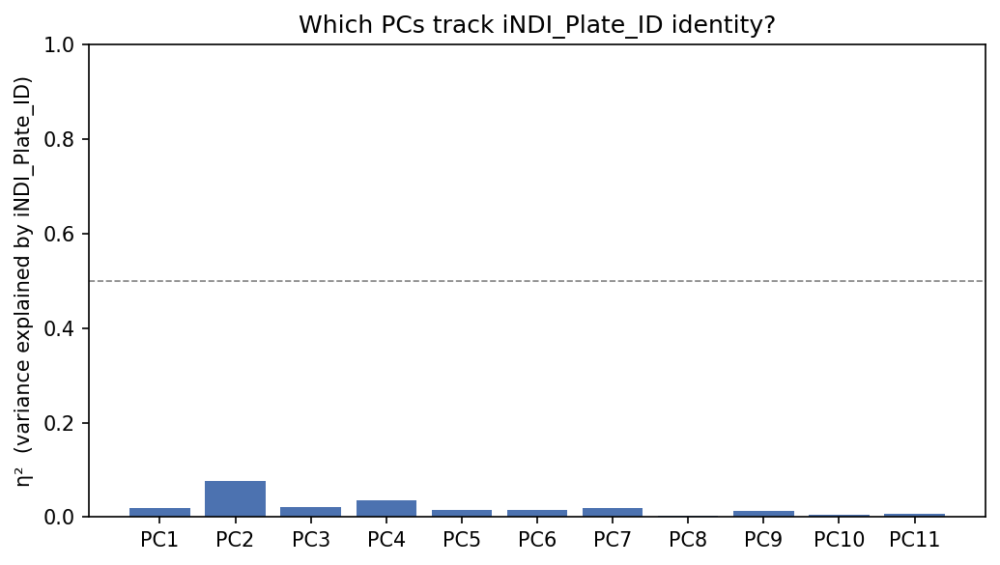

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def eta_squared(values, groups):
    """Fraction of variance in `values` explained by categorical `groups`.
    η² = SS_between / SS_total (one-way)."""
    values = np.asarray(values, dtype=float)
    grand_mean = values.mean()
    ss_total = ((values - grand_mean) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        ss_between += len(v) * (v.mean() - grand_mean) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan

# Structure

pc_cols = [c for c in df.columns if c.startswith("PC")]
groups = df["Structure"].to_numpy()

eta = pd.Series(
    {pc: eta_squared(df[pc].to_numpy(), groups) for pc in pc_cols},
    name="eta_sq",
).sort_index(key=lambda s: s.str.lstrip("PC").astype(int))

print("Variance in each PC explained by Structure (η²):")
for pc, v in eta.items():
    print(f"  {pc}: {v:.3f}")

## bar plot
fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
ax.bar(range(len(eta)), eta.values, color="#4c72b0")
ax.set_xticks(range(len(eta)))
ax.set_xticklabels(eta.index, rotation=0)
ax.set_ylabel("η²  (variance explained by Structure)")
ax.set_ylim(0, 1)
ax.axhline(0.5, ls="--", c="gray", lw=0.8)
ax.set_title("Which PCs track Structure identity?")
plt.tight_layout(); plt.show()

# Prep method

pc_cols = [c for c in df.columns if c.startswith("PC")]
groups = df["prep_method"].to_numpy()

eta = pd.Series(
    {pc: eta_squared(df[pc].to_numpy(), groups) for pc in pc_cols},
    name="eta_sq",
).sort_index(key=lambda s: s.str.lstrip("PC").astype(int))

print("Variance in each PC explained by prep_method (η²):")
for pc, v in eta.items():
    print(f"  {pc}: {v:.3f}")

## bar plot
fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
ax.bar(range(len(eta)), eta.values, color="#4c72b0")
ax.set_xticks(range(len(eta)))
ax.set_xticklabels(eta.index, rotation=0)
ax.set_ylabel("η²  (variance explained by prep_method)")
ax.set_ylim(0, 1)
ax.axhline(0.5, ls="--", c="gray", lw=0.8)
ax.set_title("Which PCs track prep_method identity?")
plt.tight_layout(); plt.show()

# Plate ID

pc_cols = [c for c in df.columns if c.startswith("PC")]
groups = df["iNDI_Plate_ID"].to_numpy()

eta = pd.Series(
    {pc: eta_squared(df[pc].to_numpy(), groups) for pc in pc_cols},
    name="eta_sq",
).sort_index(key=lambda s: s.str.lstrip("PC").astype(int))

print("Variance in each PC explained by iNDI_Plate_ID (η²):")
for pc, v in eta.items():
    print(f"  {pc}: {v:.3f}")

## bar plot
fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
ax.bar(range(len(eta)), eta.values, color="#4c72b0")
ax.set_xticks(range(len(eta)))
ax.set_xticklabels(eta.index, rotation=0)
ax.set_ylabel("η²  (variance explained by iNDI_Plate_ID)")
ax.set_ylim(0, 1)
ax.axhline(0.5, ls="--", c="gray", lw=0.8)
ax.set_title("Which PCs track iNDI_Plate_ID identity?")
plt.tight_layout(); plt.show()

/tmp/ipykernel_91923/3061083660.py:18: RuntimeWarning: Mean of empty slice.
  ss_between += len(v) * (v.mean() - grand_mean) ** 2
/vf/users/kelpschdj/conda/envs/indi_project/lib/python3.10/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


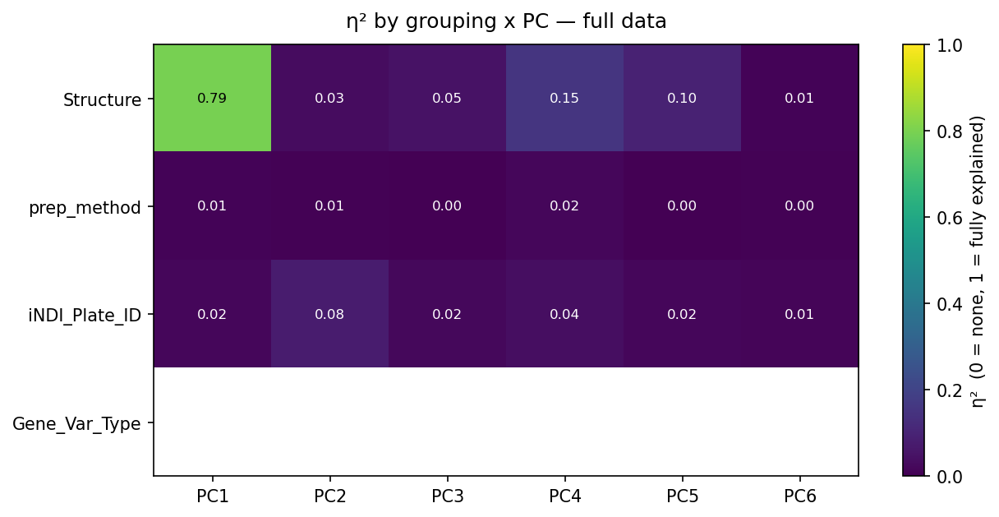

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def eta_squared(values, groups):
    """Fraction of variance in `values` explained by categorical `groups`.
    η² = SS_between / SS_total (one-way)."""
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)                 # guard against NaN/inf in a PC
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand_mean = values.mean()
    ss_total = ((values - grand_mean) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        ss_between += len(v) * (v.mean() - grand_mean) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


def eta_heatmap(data, group_cols, pc_cols=None, n_pcs=None,
                title="η²: variance in each PC explained by grouping",
                figsize=None, annot=True):
    """Heatmap of η² for each (grouping variable x PC).

    data       : dataframe with PC columns + the grouping columns
    group_cols : list of categorical column names (rows of the heatmap)
    n_pcs      : limit to first N PCs (default: all present)
    """
    if pc_cols is None:
        pc_cols = sorted(
            [c for c in data.columns if c.startswith("PC")],
            key=lambda s: int(s[2:]),
        )
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]

    # build the η² matrix: rows = grouping vars, cols = PCs
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        if gc not in data.columns:
            print(f"[warning] grouping column '{gc}' not in data; skipping.")
            continue
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)

    # plot
    if figsize is None:
        figsize = (1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5)
    fig, ax = plt.subplots(figsize=figsize, dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis", vmin=0, vmax=1,
                   aspect="auto")
    ax.set_xticks(range(len(pc_cols)))
    ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols)))
    ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="η²  (0 = none, 1 = fully explained)")
    ax.set_title(title, pad=10)

    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat


GROUP_COLS = ["Structure", "prep_method", "iNDI_Plate_ID", "Gene_Var_Type"]

# --- full (pooled) data ---
eta_full = eta_heatmap(df, GROUP_COLS, n_pcs=6,
                       title="η² by grouping x PC — full data")

All 21 plates in df have a palette color.


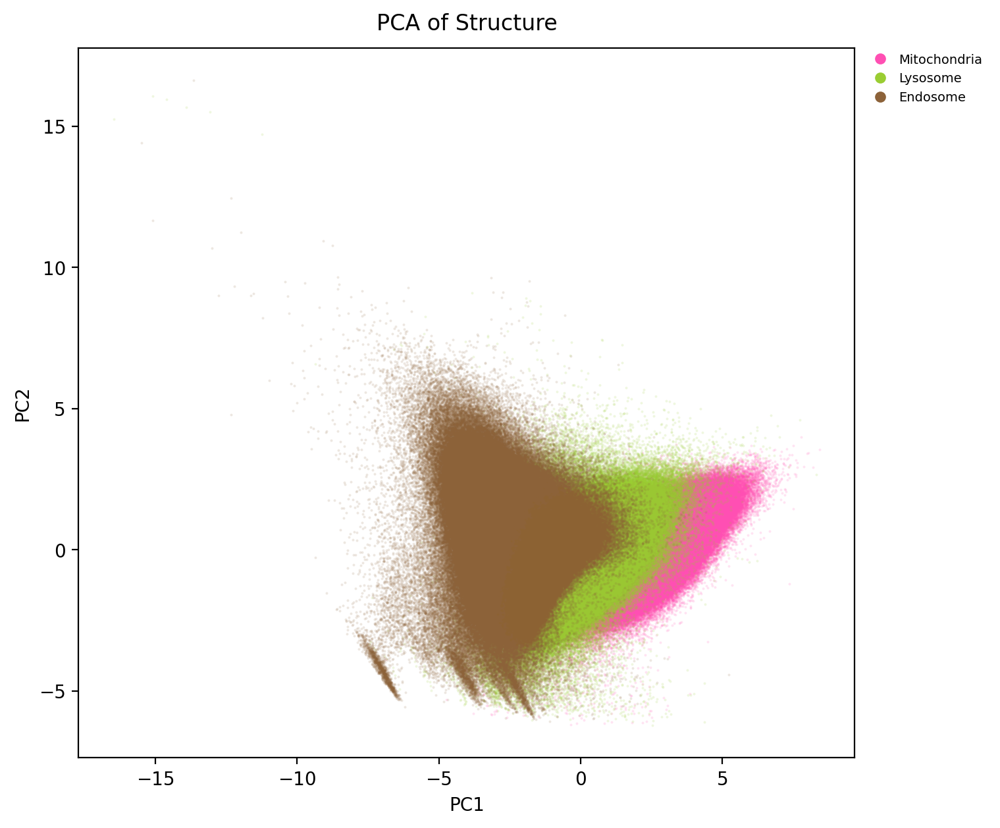

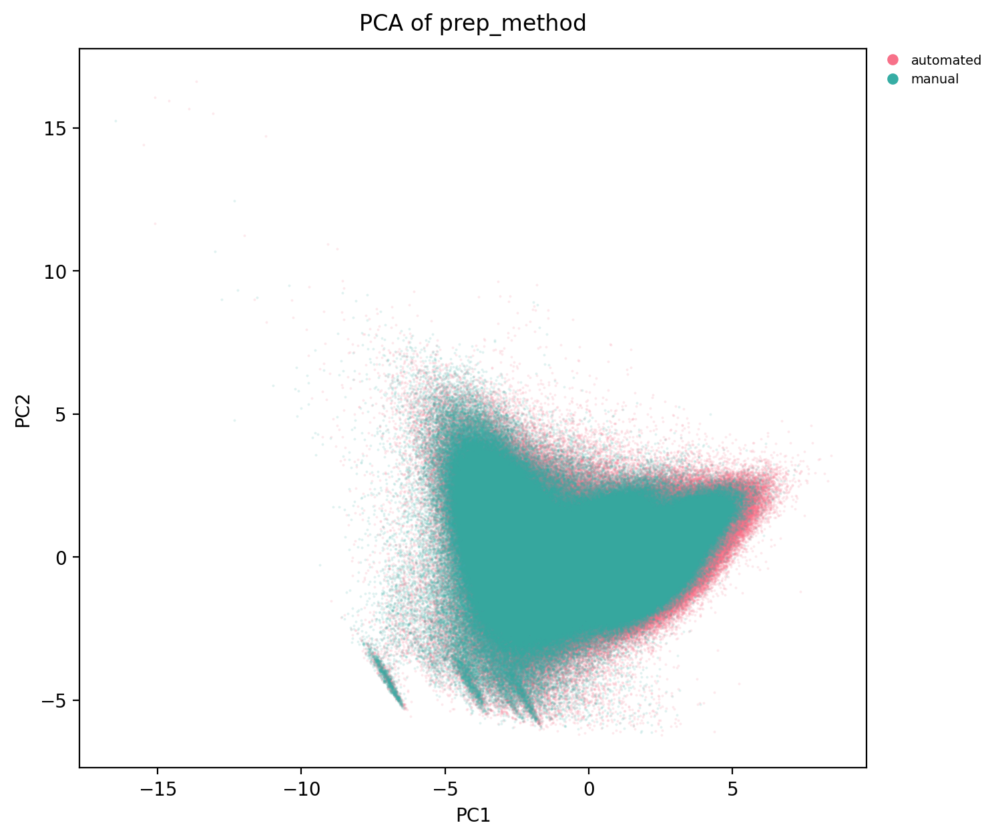

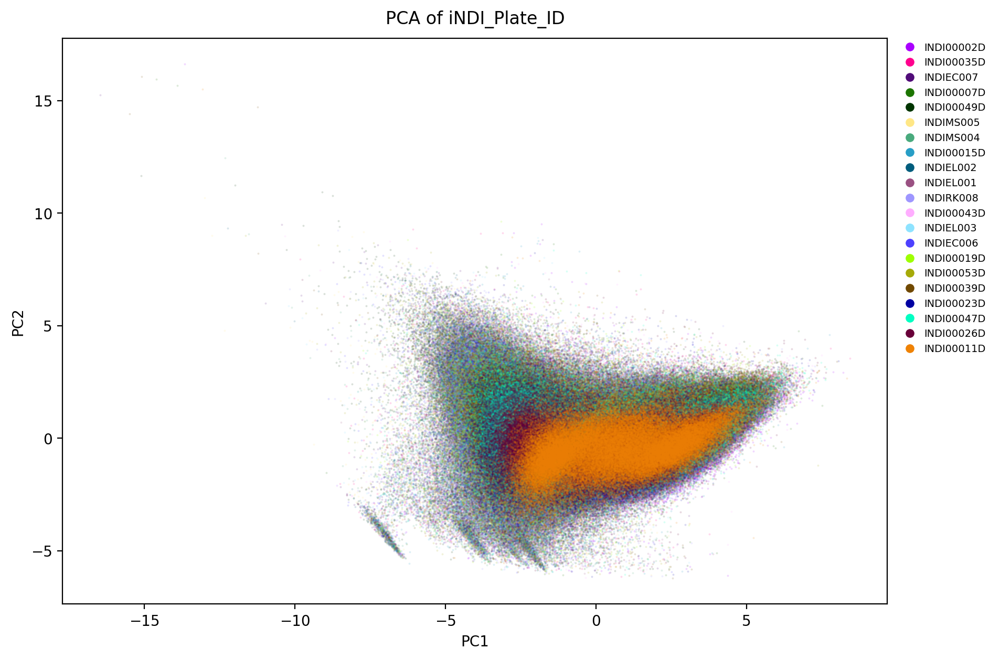

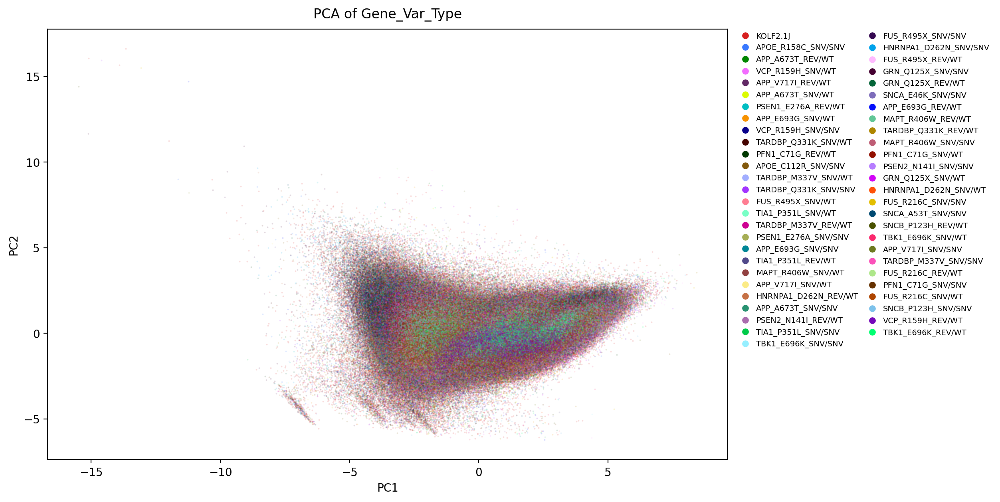

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
import seaborn as sns
import glasbey

STRUCTURE_COLORS = {
    "Golgi":        "#e6a817",
    "Endosome":     "#8c6239",
    "Lysosome":     "#9acd32",
    "Mitochondria": "#ff4fb3",
}

# --- colleague's plate palette (fixed plate_id -> color) ---
plate_palette_raw = glasbey.create_palette(
    palette_size=21, hue_bounds=(60, 500.0), chroma_bounds=(40, 130)
)
glasbey_cmap_plates = ListedColormap(plate_palette_raw)
colors_plates = [glasbey_cmap_plates(i) for i in range(len(plate_palette_raw))]

unique_plate_ids = [
    'INDI00002D', 'INDI00007D', 'INDI00011D', 'INDI00015D', 'INDI00019D',
    'INDI00023D', 'INDI00026D', 'INDI00035D', 'INDI00039D', 'INDI00043D',
    'INDI00047D', 'INDI00049D', 'INDI00053D', 'INDIEC006', 'INDIEC007',
    'INDIEL001', 'INDIEL002', 'INDIEL003', 'INDIMS004', 'INDIMS005', 'INDIRK008',
]
plate_palette = {pid: colors_plates[i] for i, pid in enumerate(unique_plate_ids)}

# glasbey palette for genotypes (high-cardinality, no fixed mapping)
geno_palette_raw = glasbey.create_palette(
    palette_size=64, hue_bounds=(0.0, 360.0), chroma_bounds=(40, 90)
)
geno_cmap = ListedColormap(geno_palette_raw)
geno_colors = [geno_cmap(i) for i in range(len(geno_palette_raw))]


def pca_scatter(
    df,
    color_col,
    pcx="PC1",
    pcy="PC2",
    palette=None,
    s=2,
    alpha=0.15,
    figsize=(10, 7),
    legend_ncol=1,
    title=None,
    show_legend=True,
):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)

    vals = df[color_col].astype("object")
    cats = vals.value_counts().index.tolist()   # freq-ordered, ALL categories

    # choose colors
    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    elif color_col == "Structure":
        colors = [STRUCTURE_COLORS.get(c, "#808080") for c in cats]
    elif color_col == "Gene_Var_Type":
        if len(cats) > len(geno_colors):
            print(f"[warning] {len(cats)} genotypes > {len(geno_colors)} "
                  f"colors; some will repeat.")
        colors = [geno_colors[i % len(geno_colors)] for i in range(len(cats))]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))

    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(
            df.loc[m, pcx], df.loc[m, pcy],
            s=s, alpha=alpha, color=col, linewidths=0, rasterized=True,
        )

    ax.set_xlabel(pcx)
    ax.set_ylabel(pcy)
    ax.set_title(title or f"PCA of {color_col}", pad=10)

    if show_legend:
        handles = [
            Line2D([0], [0], marker="o", linestyle="", markersize=5,
                   markerfacecolor=col, markeredgecolor=col, alpha=1.0, label=str(c))
            for c, col in zip(cats, colors)
        ]
        ax.legend(
            handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
            frameon=False, fontsize=7, ncol=legend_ncol,
            borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8,
        )
    plt.show()


# --- guard: plates in data with no palette color ---
plates_in_data = set(df["iNDI_Plate_ID"].dropna().unique())
missing = plates_in_data - set(plate_palette)
if missing:
    print(f"[warning] {len(missing)} plate(s) with NO palette color "
          f"(render gray): {sorted(missing)}")
else:
    print(f"All {len(plates_in_data)} plates in df have a palette color.")

df_shuf = df.sample(frac=1, random_state=0).reset_index(drop=True)

pca_scatter(df_shuf, "Structure", palette=STRUCTURE_COLORS,
            figsize=(9, 7), title="PCA of Structure")
pca_scatter(df_shuf, "prep_method",
            figsize=(9, 7), title="PCA of prep_method")
pca_scatter(df_shuf, "iNDI_Plate_ID", palette=plate_palette,
            figsize=(12, 7), title="PCA of iNDI_Plate_ID")
pca_scatter(df_shuf, "Gene_Var_Type",
            figsize=(13, 7), legend_ncol=2, title="PCA of Gene_Var_Type")

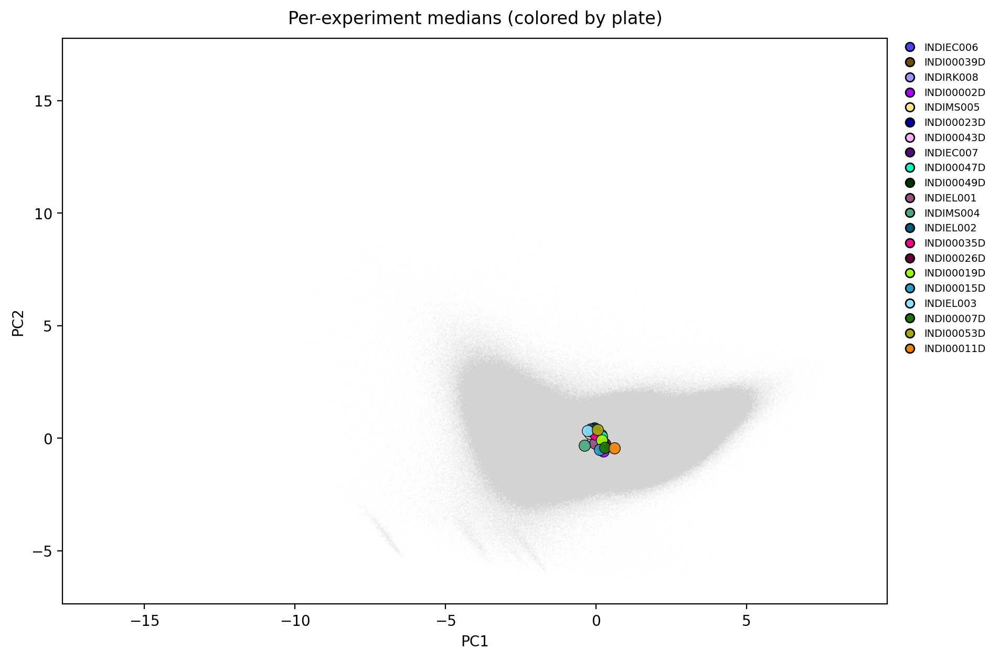

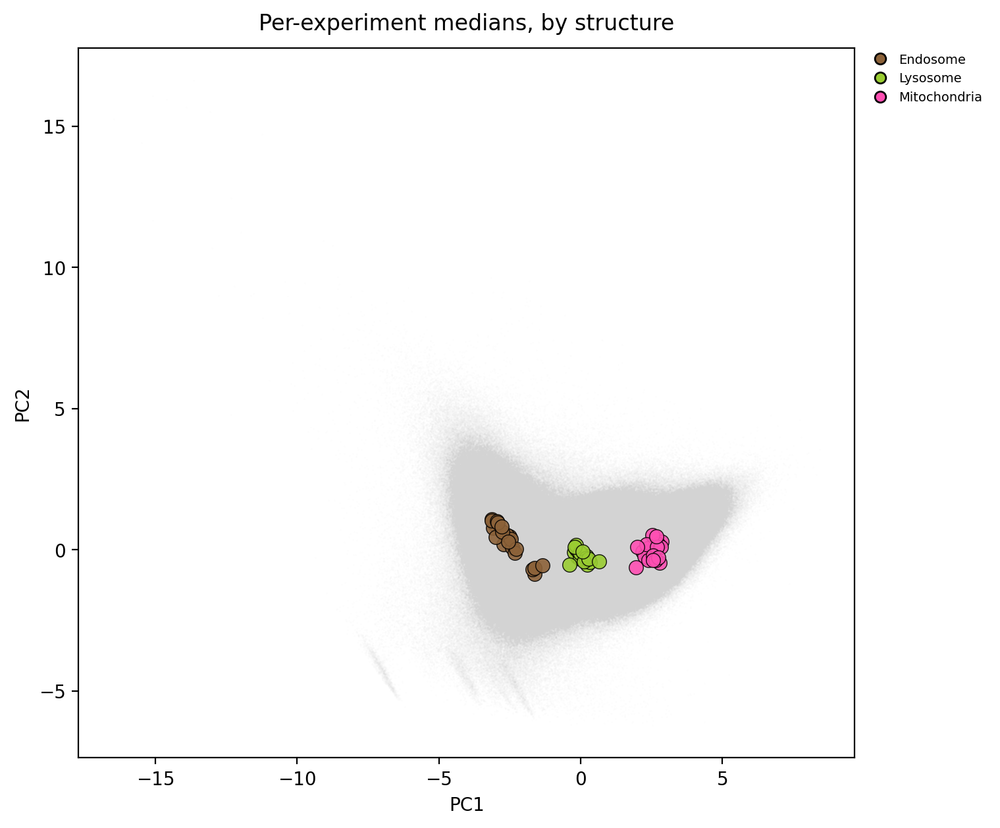

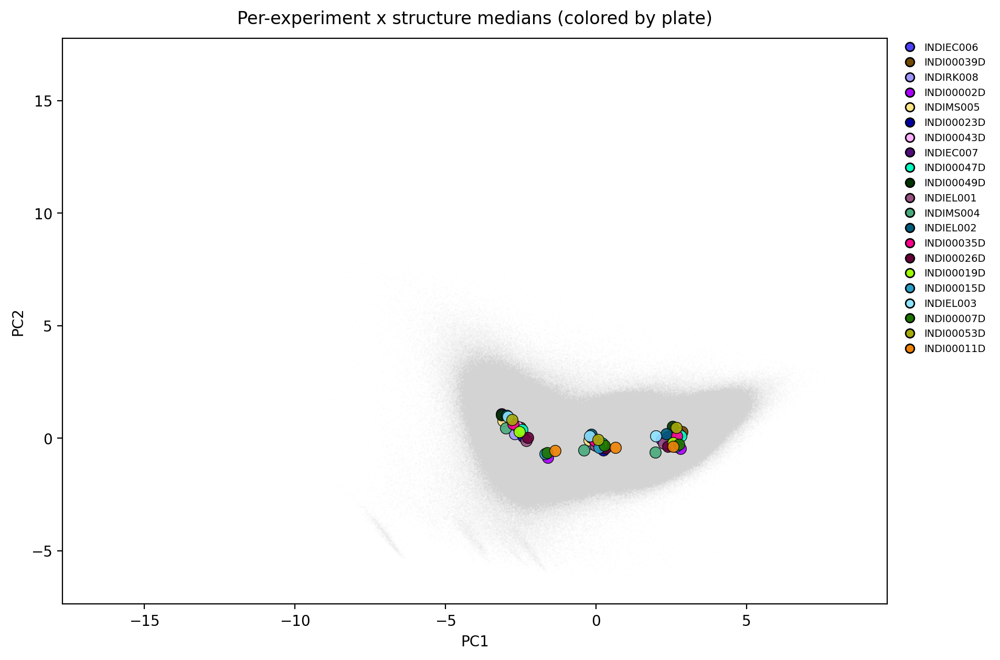

Std of per-experiment centroids, within structure (batch magnitude):
                PC1    PC2
Structure                 
Endosome      0.543  0.607
Lysosome      0.238  0.204
Mitochondria  0.260  0.304


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def centroid_overlay(
    df, color_col, group_keys,
    pcx="PC1", pcy="PC2", palette=None, stat="median",
    bg_frac=1.0, s_centroid=60, figsize=(10, 7),
    legend_ncol=1, title=None, show_legend=True,
    bg_s=1, bg_alpha=0.03,          # NEW: default to the old hardcoded values
):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)

    bg = df.sample(frac=bg_frac, random_state=0) if bg_frac < 1.0 else df
    ax.scatter(bg[pcx], bg[pcy], s=bg_s, alpha=bg_alpha, color="lightgray",
               linewidths=0, rasterized=True)          # now uses the params

    agg_spec = {pcx: stat, pcy: stat}
    if color_col not in group_keys:
        agg_spec[color_col] = "first"
    cent = df.groupby(group_keys).agg(agg_spec).reset_index()

    vals = cent[color_col].astype("object")
    cats = vals.value_counts().index.tolist()

    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    elif color_col == "Structure":
        colors = [STRUCTURE_COLORS.get(c, "#808080") for c in cats]
    elif color_col == "Gene_Var_Type":
        colors = [geno_colors[i % len(geno_colors)] for i in range(len(cats))]
    else:
        import seaborn as sns
        colors = sns.color_palette("husl", n_colors=len(cats))

    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(cent.loc[m, pcx], cent.loc[m, pcy],
                   s=s_centroid, color=col, edgecolor="k", linewidths=0.5, alpha=0.9)

    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"Per-group {stat} centroids ({color_col})", pad=10)

    if show_legend:
        handles = [
            Line2D([0], [0], marker="o", linestyle="", markersize=6,
                   markerfacecolor=col, markeredgecolor="k", label=str(c))
            for c, col in zip(cats, colors)
        ]
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
                  frameon=False, fontsize=7, ncol=legend_ncol,
                  borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8)
    plt.show()
    return cent


# --- 1) per-experiment centroids, colored by plate (batch spread) ---
# each dot = one experiment's median position; spread across plates = batch variation
centroid_overlay(
    df, color_col="iNDI_Plate_ID",
    group_keys=["Measurement_ID"],
    palette=plate_palette,
    title="Per-experiment medians (colored by plate)",
    figsize=(12, 7),
)

# --- 2) per-experiment x structure centroids, colored by structure ---
centroid_overlay(
    df, color_col="Structure",
    group_keys=["Measurement_ID", "Structure"],
    palette=STRUCTURE_COLORS,
    title="Per-experiment medians, by structure",
    figsize=(9, 7),
)

# --- 3) per-experiment x structure centroids, colored by plate ---
# tightest read on batch: within each structure blob, how far apart are plates?
centroid_overlay(
    df, color_col="iNDI_Plate_ID",
    group_keys=["Measurement_ID", "Structure"],
    palette=plate_palette,
    title="Per-experiment x structure medians (colored by plate)",
    figsize=(12, 7),
)

# batch spread = how much experiment centroids vary within each structure
cent = df.groupby(["Measurement_ID", "Structure"])[["PC1", "PC2"]].median().reset_index()
spread = cent.groupby("Structure")[["PC1", "PC2"]].std()
print("Std of per-experiment centroids, within structure (batch magnitude):")
print(spread.round(3))

In [ ]:
cent = df.groupby(["iNDI_Plate_ID", "Structure"])[["PC1", "PC2"]].median().reset_index()

# distance of each plate's centroid from the per-structure grand centroid
grand = cent.groupby("Structure")[["PC1","PC2"]].transform("median")
cent["dist"] = np.sqrt((cent["PC1"]-grand["PC1"])**2 + (cent["PC2"]-grand["PC2"])**2)

print("Most off-center Parental plate centroids (per structure):")
print(cent.sort_values("dist", ascending=False).head(10).round(2).to_string(index=False))

Most off-center Parental plate centroids (per structure):
iNDI_Plate_ID    Structure   PC1   PC2  dist
   INDI00002D     Endosome -1.61 -0.85  1.64
   INDI00011D     Endosome -1.35 -0.54  1.60
   INDI00007D     Endosome -1.62 -0.65  1.48
   INDI00015D     Endosome -1.69 -0.69  1.46
    INDIEC007     Endosome -3.14  1.08  0.82
    INDIMS004 Mitochondria  1.96 -0.61  0.82
   INDI00049D     Endosome -3.13  1.03  0.78
    INDIEL002     Endosome -2.95  1.01  0.66
    INDIEC006     Endosome -3.04  0.91  0.63
    INDIEL001     Endosome -2.32 -0.10  0.63


Points in streak region:
  n = 5845
  organelle_count value counts:
organelle_count
1.0     3313
2.0     1423
3.0      499
4.0      282
5.0      134
6.0       92
7.0       47
8.0       20
9.0       18
10.0       7
  Structure breakdown:
Structure
Endosome        5563
Lysosome         275
Mitochondria       7


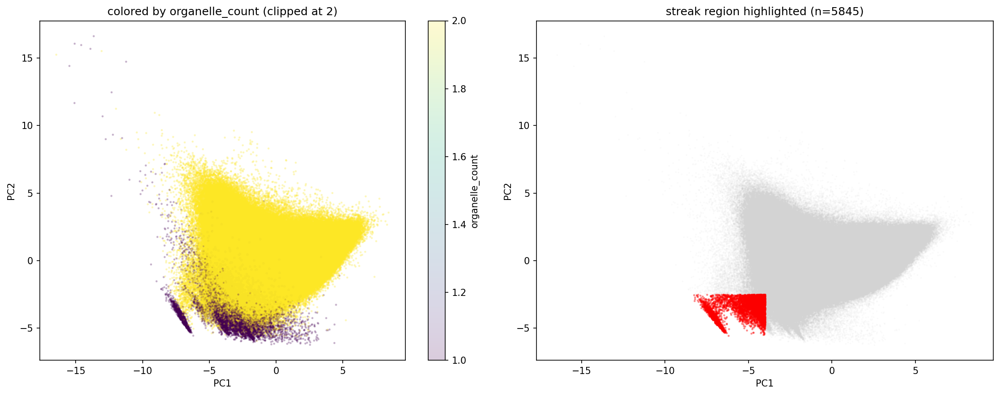

In [ ]:
# What are the streaks?
# Mostly single endosomes in ROIs

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# left: color by organelle_count (clipped so low counts are visible)
sc = ax[0].scatter(df_shuf["PC1"], df_shuf["PC2"],
                   c=df_shuf["organelle_count"].clip(upper=2),
                   s=2, alpha=0.2, cmap="viridis", rasterized=True)
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
ax[0].set_title("colored by organelle_count (clipped at 2)")
plt.colorbar(sc, ax=ax[0], label="organelle_count")

# right: isolate just the streak region and low counts
streak = df_shuf[(df_shuf["PC2"] < -2.5) & (df_shuf["PC1"] < -4)]
print("Points in streak region:")
print("  n =", len(streak))
print("  organelle_count value counts:")
print(streak["organelle_count"].value_counts().head(10).to_string())
print("  Structure breakdown:")
print(streak["Structure"].value_counts().to_string())

ax[1].scatter(df_shuf["PC1"], df_shuf["PC2"], s=1, alpha=0.05,
             color="lightgray", rasterized=True)
ax[1].scatter(streak["PC1"], streak["PC2"], s=2, alpha=0.3,
             color="red", rasterized=True)
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
ax[1].set_title(f"streak region highlighted (n={len(streak)})")
plt.tight_layout(); plt.show()

Image-level: 581399 rows (13440 images x 3 structures)
Well-level: 17802 rows
  Structure                        Measurement_ID subdirectory     area_px  \
0  Endosome  028ebee9-afaf-4ff8-b435-af11714285dc       r02c03  547.828571   
1  Endosome  028ebee9-afaf-4ff8-b435-af11714285dc       r02c04  576.439394   
2  Endosome  028ebee9-afaf-4ff8-b435-af11714285dc       r02c05  574.757143   
3  Endosome  028ebee9-afaf-4ff8-b435-af11714285dc       r02c06  646.971429   
4  Endosome  028ebee9-afaf-4ff8-b435-af11714285dc       r02c07  648.590909   

   organelle_count  roi_occupancy  mean_f_intensity  CoefOfVar_intensity  \
0        28.257143       0.012110       7200.389388             0.407569   
1        26.257576       0.012742       9082.195201             0.399618   
2        31.342857       0.012705       6465.318314             0.416983   
3        28.471429       0.014301       8150.295209             0.420743   
4        25.984848       0.014337       7534.606623             0.468567 

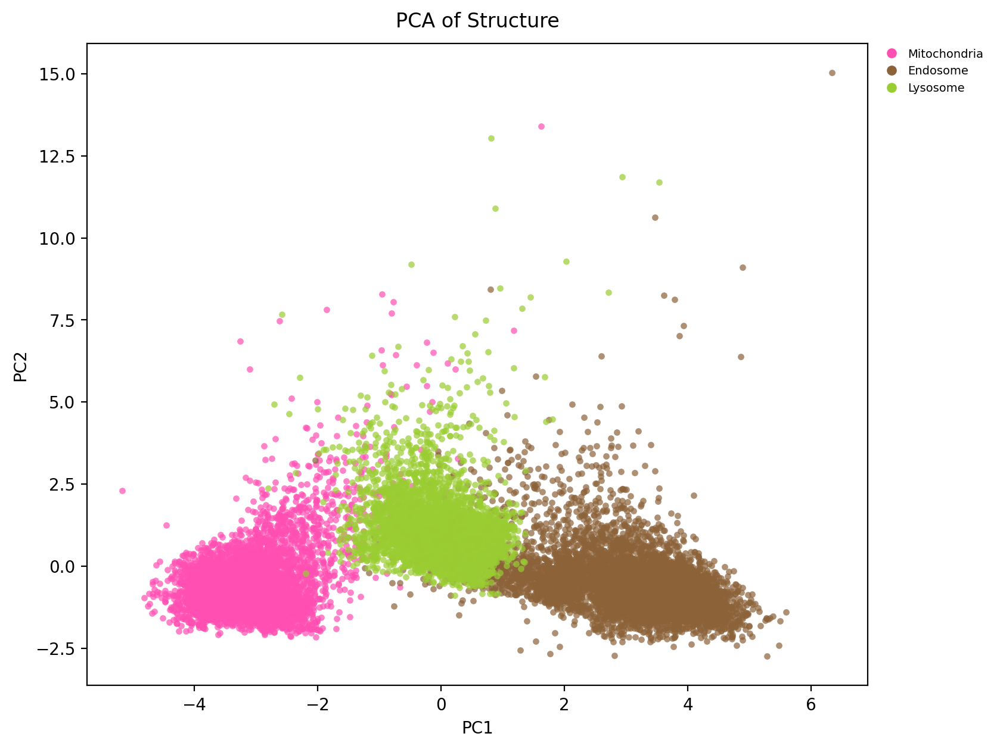

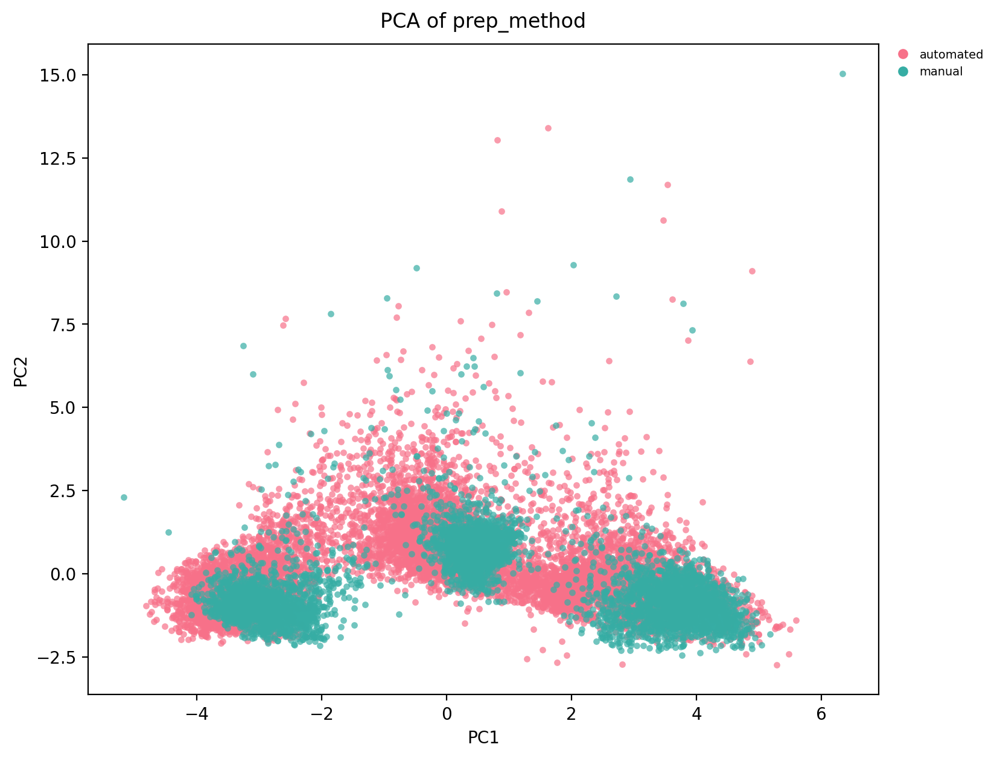

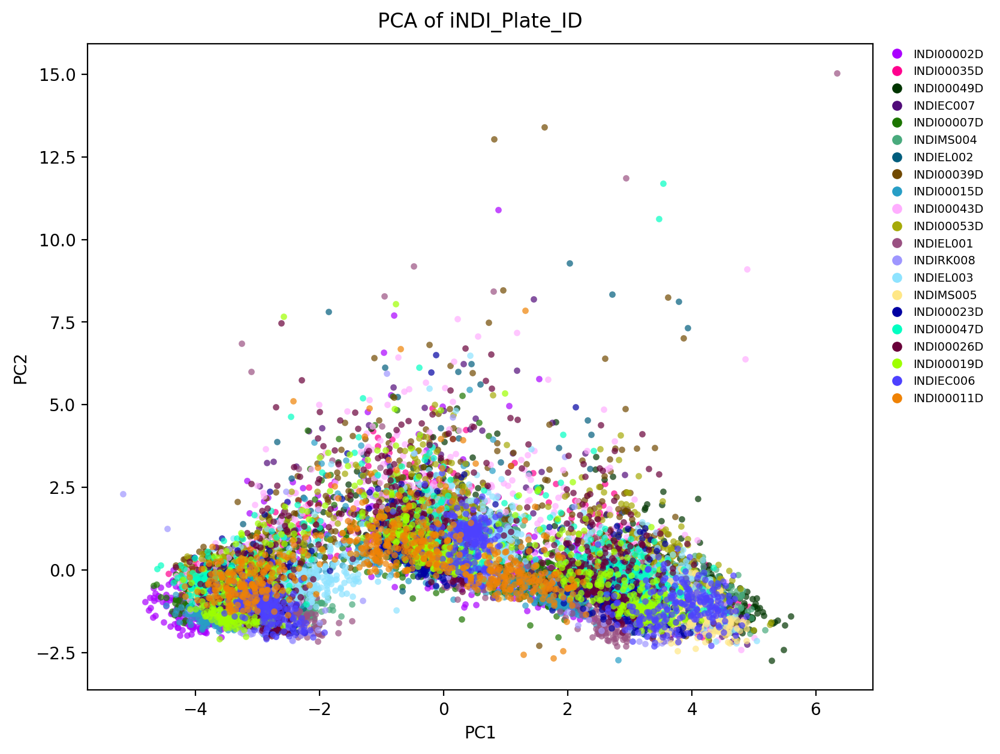

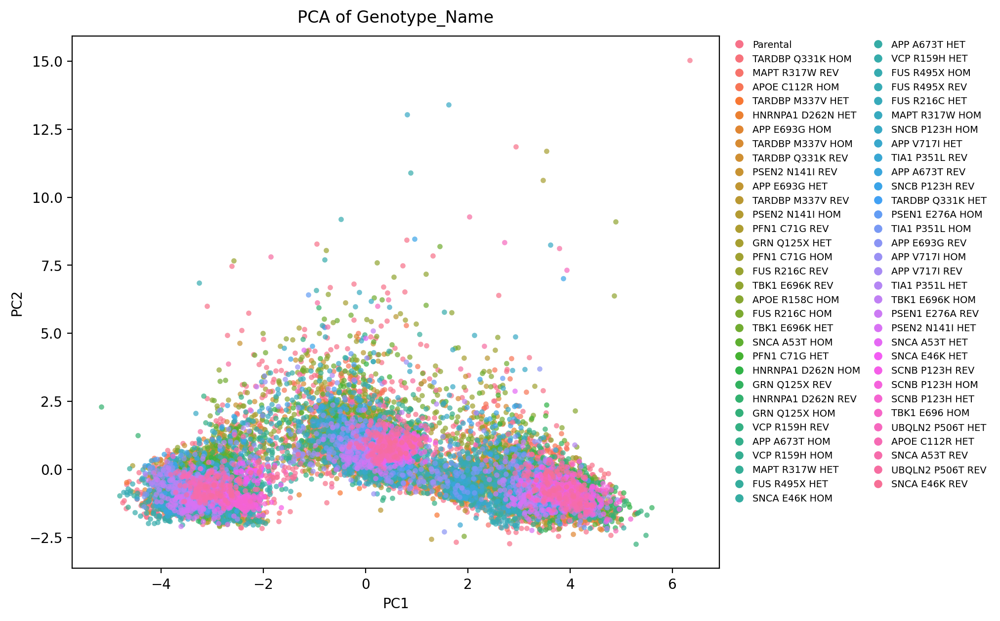

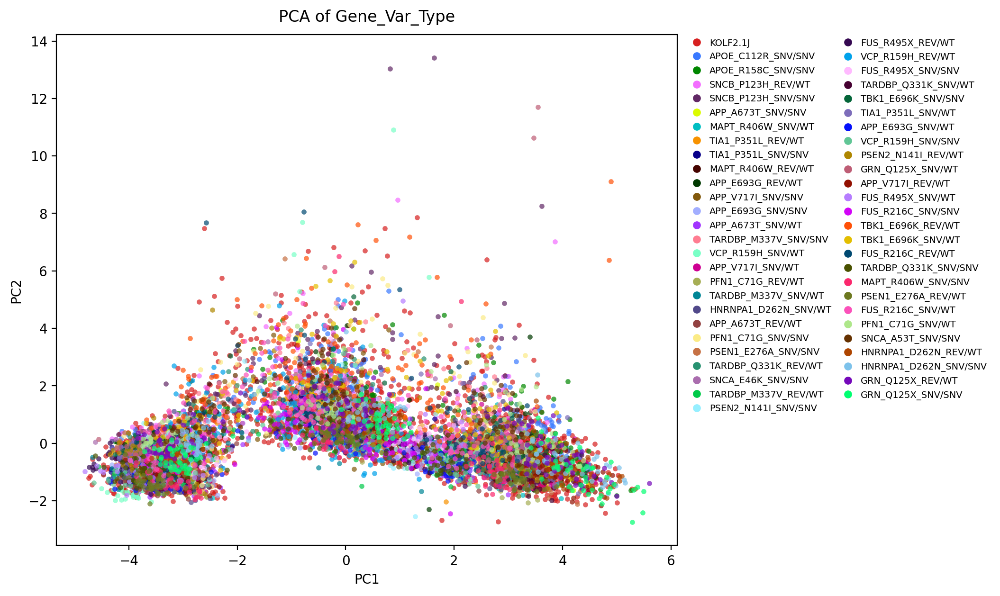

In [ ]:
import pandas as pd

WELL_KEYS  = ["Measurement_ID", "subdirectory"]
IMAGE_KEY  = "DAPI_filename"
STRUCT_KEY = "Structure"

# metadata columns to carry through (identical within a group) — take .first()
# everything that isn't a feature, a PC, or a grouping key
GROUP_KEYS = [STRUCT_KEY, *WELL_KEYS, IMAGE_KEY]
DROP_COLS  = set(FEATURES) | {"PC1", "PC2", "PC3"} | set(GROUP_KEYS) \
             | {"Nucleus_ID", "channel_filename"}   # per-ROI, not meaningful post-agg
META_COLS  = [c for c in df.columns if c not in DROP_COLS]

# --- stage 1: median across ROIs within each image (per structure) ---
agg_image = {**{f: "median" for f in FEATURES},
             **{m: "first" for m in META_COLS}}
image_level = (
    df.groupby(GROUP_KEYS, as_index=False)
      .agg(agg_image)
)
print(f"Image-level: {len(image_level)} rows "
      f"({df[IMAGE_KEY].nunique()} images x {df[STRUCT_KEY].nunique()} structures)")

# --- stage 2: mean across images within each well (per structure) ---
WELL_GROUP = [STRUCT_KEY, *WELL_KEYS]
agg_well = {**{f: "mean" for f in FEATURES},
            **{m: "first" for m in META_COLS}}
well_level = (
    image_level.groupby(WELL_GROUP, as_index=False)
      .agg(agg_well)
)
print(f"Well-level: {len(well_level)} rows")
print(well_level.head())

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# fit PCA on the WELL-LEVEL aggregated features (each row = one well x structure)
Xw_df = well_level[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = Xw_df.notna().all(axis=1)
well_level = well_level[keep].reset_index(drop=True)
Xw_df = Xw_df[keep].reset_index(drop=True)
print(f"Well-level PCA on {len(well_level)} rows "
      f"(dropped {(~keep).sum()} with NaN)")

Xw = StandardScaler().fit_transform(Xw_df.values)
pca_well = PCA(n_components=len(FEATURES))
scores_w = pca_well.fit_transform(Xw)
well_level["PC1"], well_level["PC2"], well_level["PC3"] = \
    scores_w[:, 0], scores_w[:, 1], scores_w[:, 2]

# scree + explained variance
evw = pca_well.explained_variance_ratio_
print("Well-level PC1-3:", evw[:3].round(3), "cumulative:", np.cumsum(evw)[:3].round(3))

# reuse your scatter + palette
pca_well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(pca_well_shuf, "Structure", palette=STRUCTURE_COLORS, s=15, alpha=0.7)
pca_scatter(pca_well_shuf, "prep_method", s=15, alpha=0.7, title="PCA of prep_method")
pca_scatter(pca_well_shuf, "iNDI_Plate_ID", palette=plate_palette, s=15, alpha=0.7, title="PCA of iNDI_Plate_ID")
pca_scatter(pca_well_shuf, "Genotype_Name", s=15, alpha=0.7, title="PCA of Genotype_Name", legend_ncol=2)
pca_scatter(pca_well_shuf, "Gene_Var_Type", s=15, alpha=0.7, title="PCA of Gene_Var_Type", legend_ncol=2)

In [ ]:
print(well_level.head())

  Structure                        Measurement_ID subdirectory     area_px  \
0  Endosome  028ebee9-afaf-4ff8-b435-af11714285dc       r02c03  547.828571   
1  Endosome  028ebee9-afaf-4ff8-b435-af11714285dc       r02c04  576.439394   
2  Endosome  028ebee9-afaf-4ff8-b435-af11714285dc       r02c05  574.757143   
3  Endosome  028ebee9-afaf-4ff8-b435-af11714285dc       r02c06  646.971429   
4  Endosome  028ebee9-afaf-4ff8-b435-af11714285dc       r02c07  648.590909   

   organelle_count  roi_occupancy  mean_f_intensity  CoefOfVar_intensity  \
0        28.257143       0.012110       7200.389388             0.407569   
1        26.257576       0.012742       9082.195201             0.399618   
2        31.342857       0.012705       6465.318314             0.416983   
3        28.471429       0.014301       8150.295209             0.420743   
4        25.984848       0.014337       7534.606623             0.468567   

   eccentricity_median  solidity_median  ...       PC5       PC6       PC7

# Parentals

Parental rows: 731557  (21 experiments, 21 plates, 3 structures)

Parental nuclei per plate (per structure ~ this/3):
iNDI_Plate_ID
INDI00002D    60215
INDI00019D    59875
INDI00043D    56027
INDI00035D    54332
INDI00049D    45693
INDI00053D    44182
INDI00039D    42268
INDI00023D    42044
INDI00007D    39231
INDI00011D    39189
INDI00047D    38533
INDIMS005     31231
INDI00015D    28857
INDIEL001     25040
INDIEL002     24026
INDIEC007     23443
INDIMS004     22535
INDIEC006     21745
INDI00026D    20824
INDIRK008      7416
INDIEL003      4851


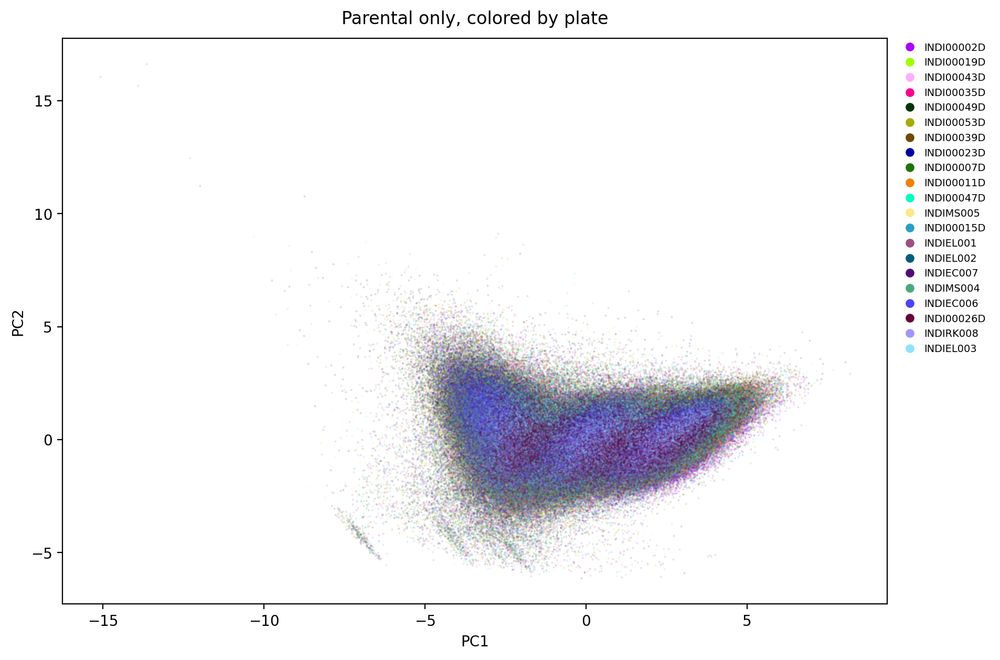

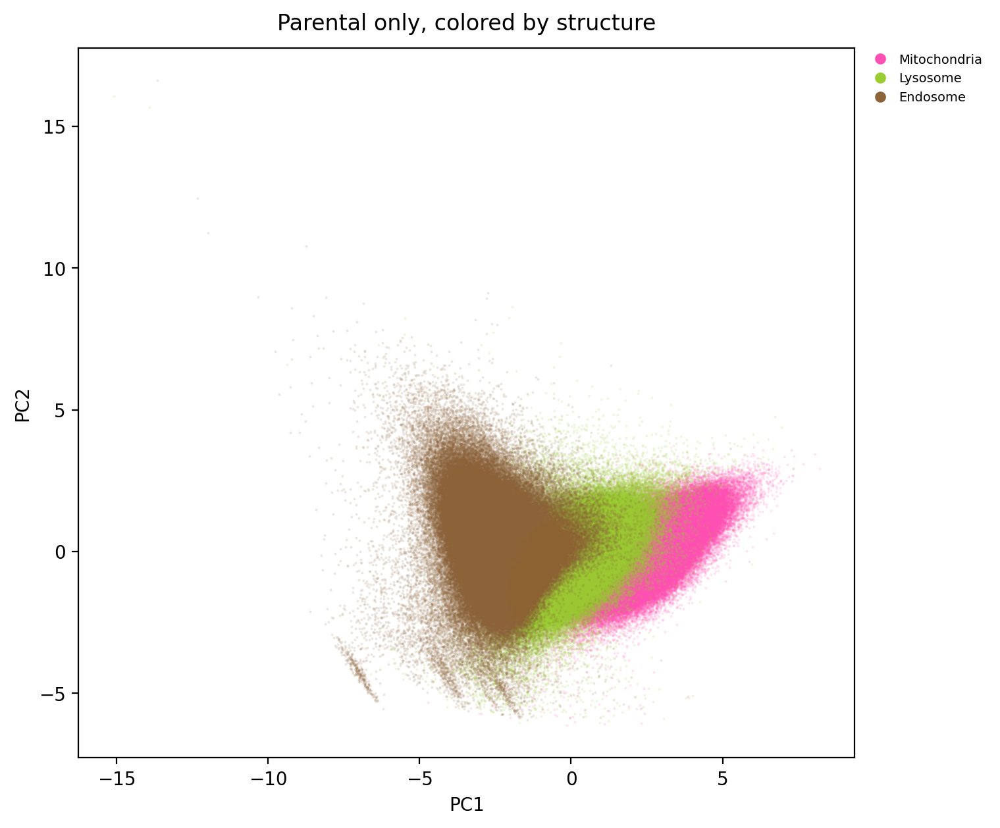

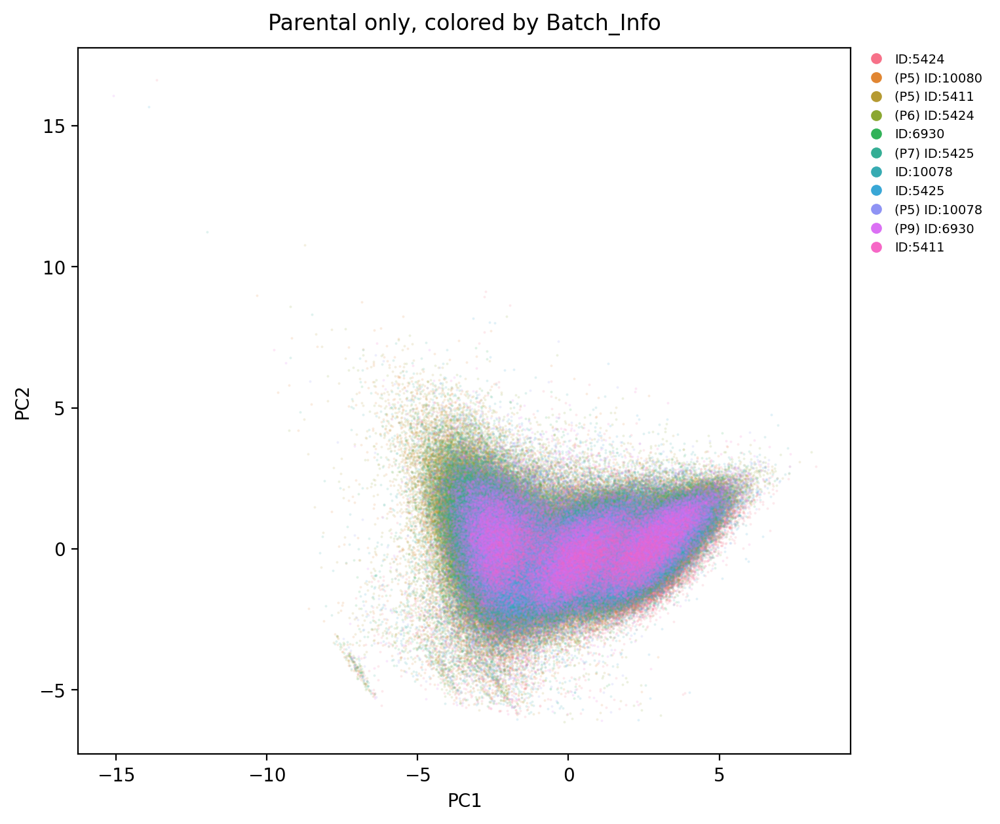

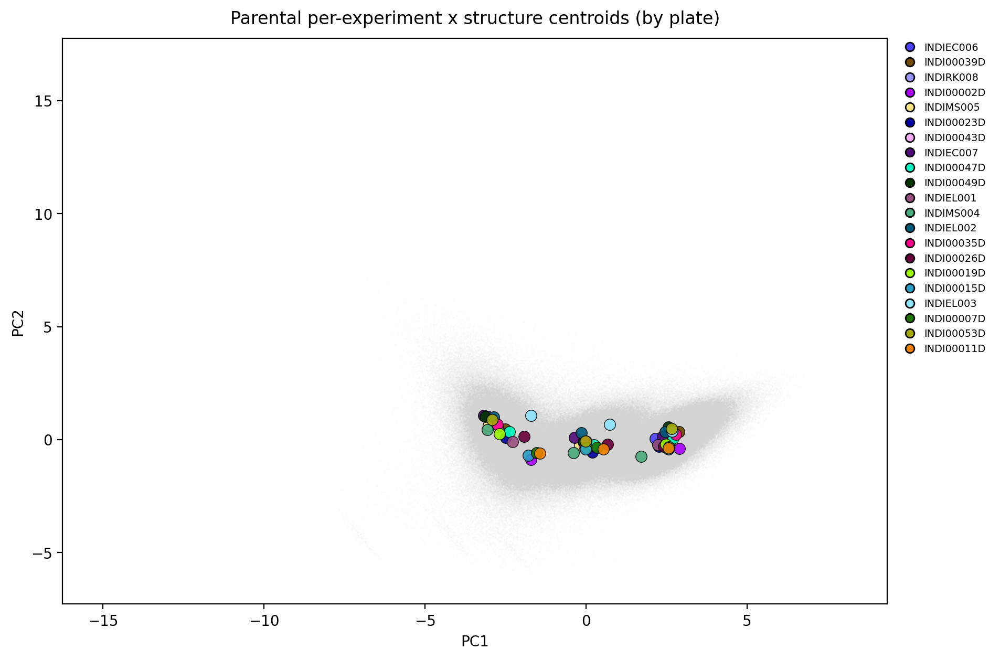

Parental batch spread (std of experiment centroids, within structure):
                PC1    PC2    PC3
Structure                        
Endosome      0.565  0.615  0.477
Lysosome      0.300  0.289  0.208
Mitochondria  0.271  0.350  0.181


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- subset to Parental (adjust the label if it's stored differently) ---
PARENTAL_LABEL = "Parental"
par = df[df["Genotype_Name"] == PARENTAL_LABEL].copy()
print(f"Parental rows: {len(par)}  ({par['Measurement_ID'].nunique()} experiments, "
      f"{par['iNDI_Plate_ID'].nunique()} plates, {par['Structure'].nunique()} structures)")

# how many Parental nuclei per plate? (can you normalize to it on every plate?)
print("\nParental nuclei per plate (per structure ~ this/3):")
print(par.groupby("iNDI_Plate_ID").size().sort_values(ascending=False).to_string())

par_shuf = par.sample(frac=1, random_state=0).reset_index(drop=True)

# Parental colored by plate — spread here = batch effect on wild-type
pca_scatter(par_shuf, "iNDI_Plate_ID", palette=plate_palette,
            figsize=(12, 7), title="Parental only, colored by plate")

# Parental colored by structure — should still show the 3 structure blobs
pca_scatter(par_shuf, "Structure", palette=STRUCTURE_COLORS,
            figsize=(9, 7), title="Parental only, colored by structure")

pca_scatter(par_shuf, "Batch_Info",
            figsize=(9, 7), title="Parental only, colored by Batch_Info")

# per-plate centroids over the Parental cloud (quantify batch spread)
cent = centroid_overlay(
    par, color_col="iNDI_Plate_ID",
    group_keys=["Measurement_ID", "Structure"],
    palette=plate_palette, bg_frac=1.0,
    title="Parental per-experiment x structure centroids (by plate)",
    figsize=(12, 7),
)

# batch magnitude on Parental: std of per-experiment centroids within structure
par_cent = par.groupby(["Measurement_ID", "Structure"])[["PC1", "PC2", "PC3"]].median().reset_index()
print("Parental batch spread (std of experiment centroids, within structure):")
print(par_cent.groupby("Structure")[["PC1", "PC2", "PC3"]].std().round(3))

Most off-center Parental plate centroids (per structure):
iNDI_Plate_ID    Structure   PC1   PC2  dist
   INDI00002D     Endosome -1.71 -0.89  1.64
   INDI00011D     Endosome -1.44 -0.60  1.60
   INDI00007D     Endosome -1.53 -0.58  1.52
   INDI00015D     Endosome -1.79 -0.70  1.43
    INDIEL003     Lysosome  0.74  0.68  1.18
    INDIEL003     Endosome -1.71  1.06  1.13
    INDIMS004 Mitochondria  1.72 -0.74  1.10
    INDIEC007     Endosome -3.18  1.07  0.82
   INDI00026D     Endosome -1.93  0.13  0.79
   INDI00049D     Endosome -3.12  1.02  0.74


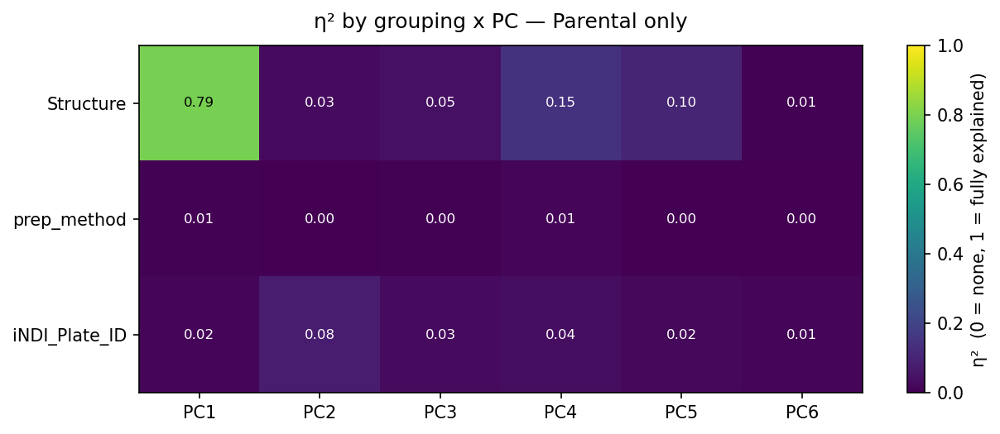

In [ ]:
par = df[df["Genotype_Name"] == "Parental"]
cent = par.groupby(["iNDI_Plate_ID", "Structure"])[["PC1","PC2"]].median().reset_index()

# distance of each plate's centroid from the per-structure grand centroid
grand = cent.groupby("Structure")[["PC1","PC2"]].transform("median")
cent["dist"] = np.sqrt((cent["PC1"]-grand["PC1"])**2 + (cent["PC2"]-grand["PC2"])**2)

print("Most off-center Parental plate centroids (per structure):")
print(cent.sort_values("dist", ascending=False).head(10).round(2).to_string(index=False))

par = df[df["Genotype_Name"] == "Parental"]
eta_par = eta_heatmap(
    par, ["Structure", "prep_method", "iNDI_Plate_ID"],
    n_pcs=6, title="η² by grouping x PC — Parental only",
)

Automated-only: 1737032 rows (1199175 manual rows dropped, 40.8%)
  13 plates, 53 genotypes, 3 structures
PCA on 1737032 rows (dropped 0 NaN)
Automated-only EVR: [0.472 0.138 0.121 0.088 0.069] | cumulative: [0.472 0.609 0.73  0.818 0.887]


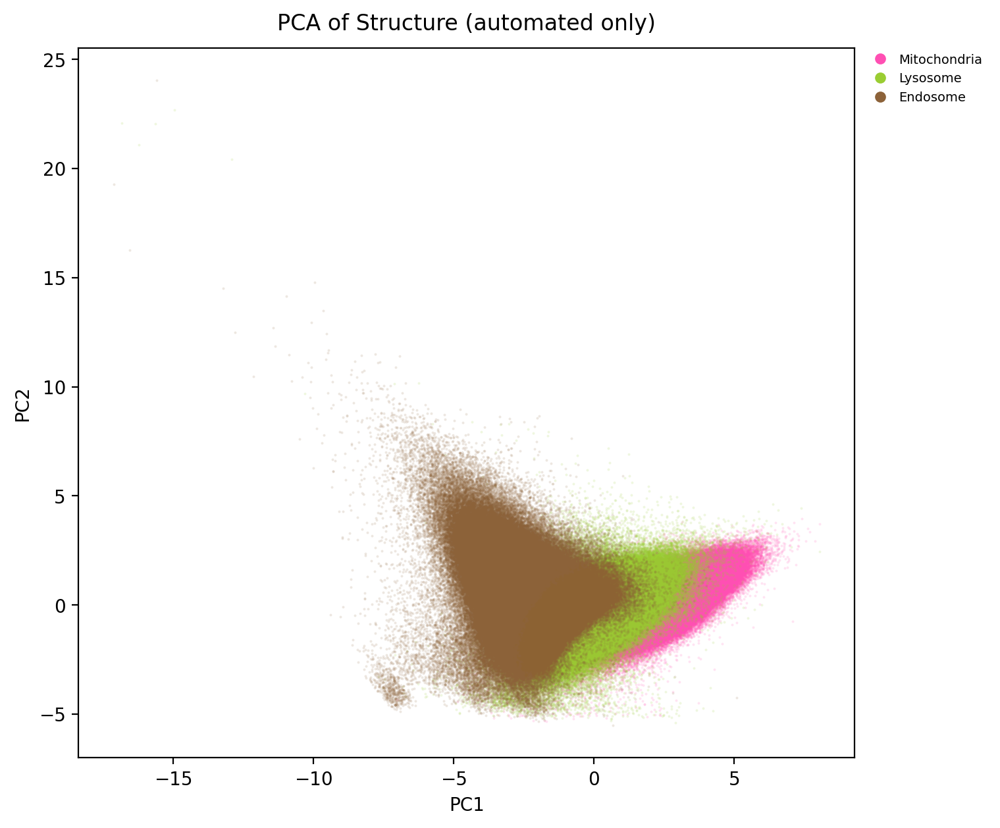

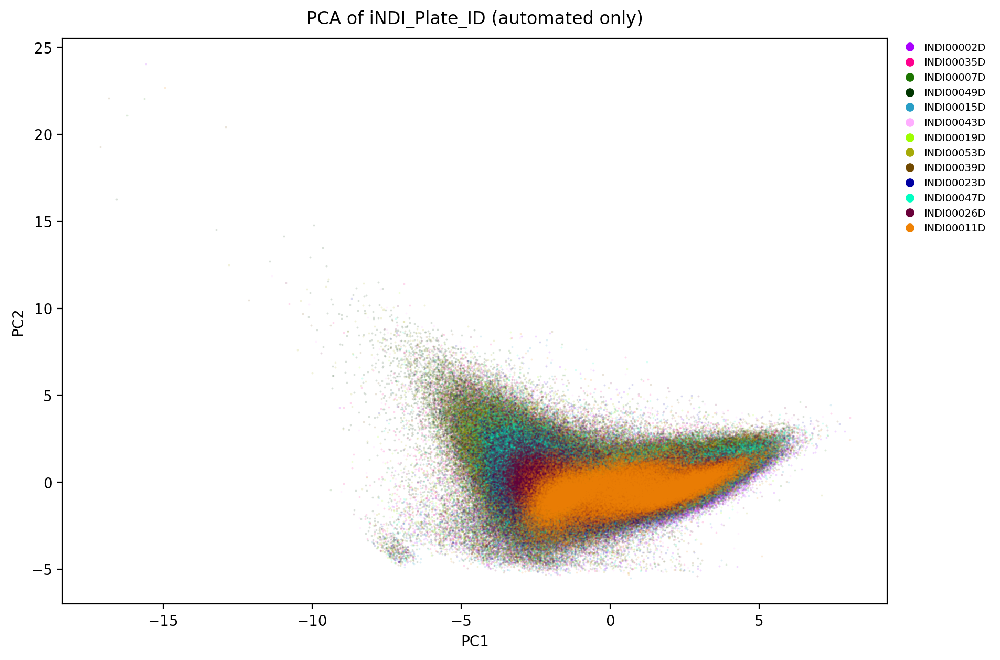

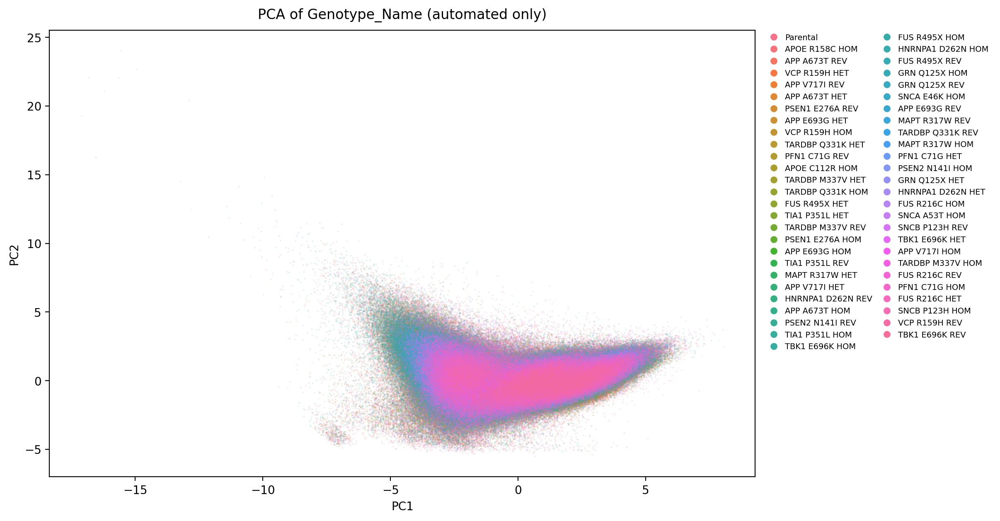

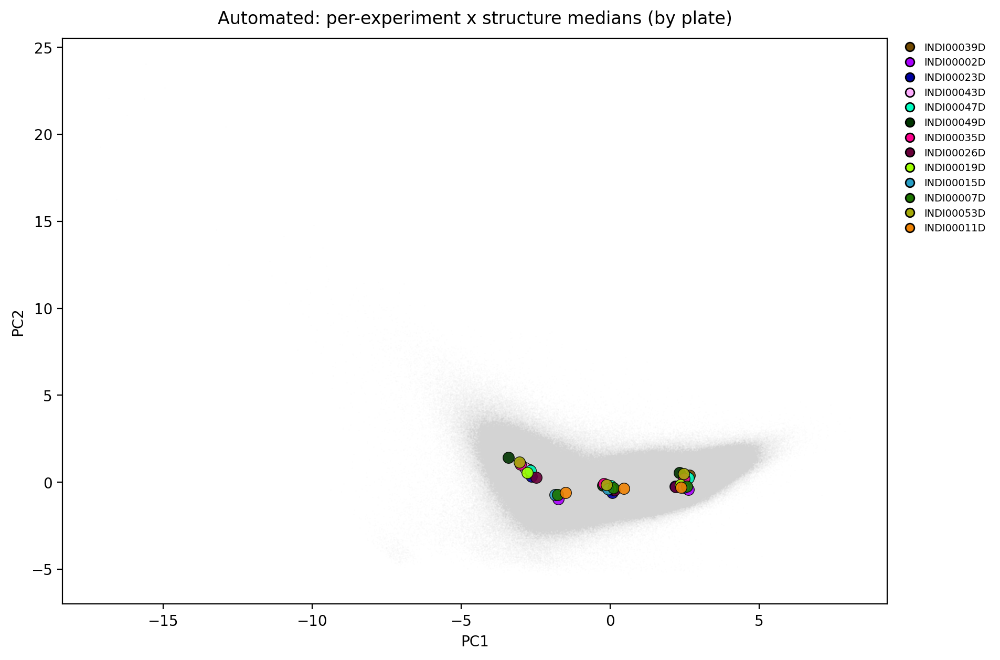

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# --- subset to automated prep only ---
auto = df[df["prep_method"] == "automated"].copy()
print(f"Automated-only: {len(auto)} rows "
      f"({len(df) - len(auto)} manual rows dropped, "
      f"{(len(df)-len(auto))/len(df)*100:.1f}%)")
print(f"  {auto['iNDI_Plate_ID'].nunique()} plates, "
      f"{auto['Genotype_Name'].nunique()} genotypes, "
      f"{auto['Structure'].nunique()} structures")

# --- refit PCA on automated data only (don't reuse the pooled fit) ---
X_df = auto[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = X_df.notna().all(axis=1)
auto = auto[keep].reset_index(drop=True)
X_df = X_df[keep].reset_index(drop=True)
print(f"PCA on {len(auto)} rows (dropped {(~keep).sum()} NaN)")

scaler_auto = StandardScaler()
X = scaler_auto.fit_transform(X_df.values)
pca_auto = PCA(n_components=len(FEATURES))
scores = pca_auto.fit_transform(X)
for i in range(scores.shape[1]): 
    auto[f"PC{i+1}"] = scores[:, i]

ev = pca_auto.explained_variance_ratio_
print("Automated-only EVR:", ev[:5].round(3), "| cumulative:", np.cumsum(ev)[:5].round(3))

# --- standard panels ---
auto_shuf = auto.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(auto_shuf, "Structure", palette=STRUCTURE_COLORS,
            figsize=(9, 7), title="PCA of Structure (automated only)")
pca_scatter(auto_shuf, "iNDI_Plate_ID", palette=plate_palette,
            figsize=(12, 7), title="PCA of iNDI_Plate_ID (automated only)")
pca_scatter(auto_shuf, "Genotype_Name",
            figsize=(13, 7), legend_ncol=2, title="PCA of Genotype_Name (automated only)")

# --- per-experiment x structure median centroids, colored by plate ---
# batch spread within the automated cohort (13 D-plates)
cent_auto = centroid_overlay(
    auto, color_col="iNDI_Plate_ID",
    group_keys=["Measurement_ID", "Structure"],
    palette=plate_palette, stat="median", bg_frac=1.0,
    title="Automated: per-experiment x structure medians (by plate)",
    figsize=(12, 7),
)

Genotype_Name: 0 well(s) with >1 value
iNDI_Plate_ID: 0 well(s) with >1 value
prep_method: 0 well(s) with >1 value

Image-level: 357431 rows (13440 images x 3 structures)
Well-level: 11219 rows (3740 wells x structures)

Well-level PCA on 11219 rows (dropped 0 NaN)
Well-level EVR: [0.594 0.14  0.087 0.075 0.06 ] | cumulative: [0.594 0.734 0.82  0.895 0.955]


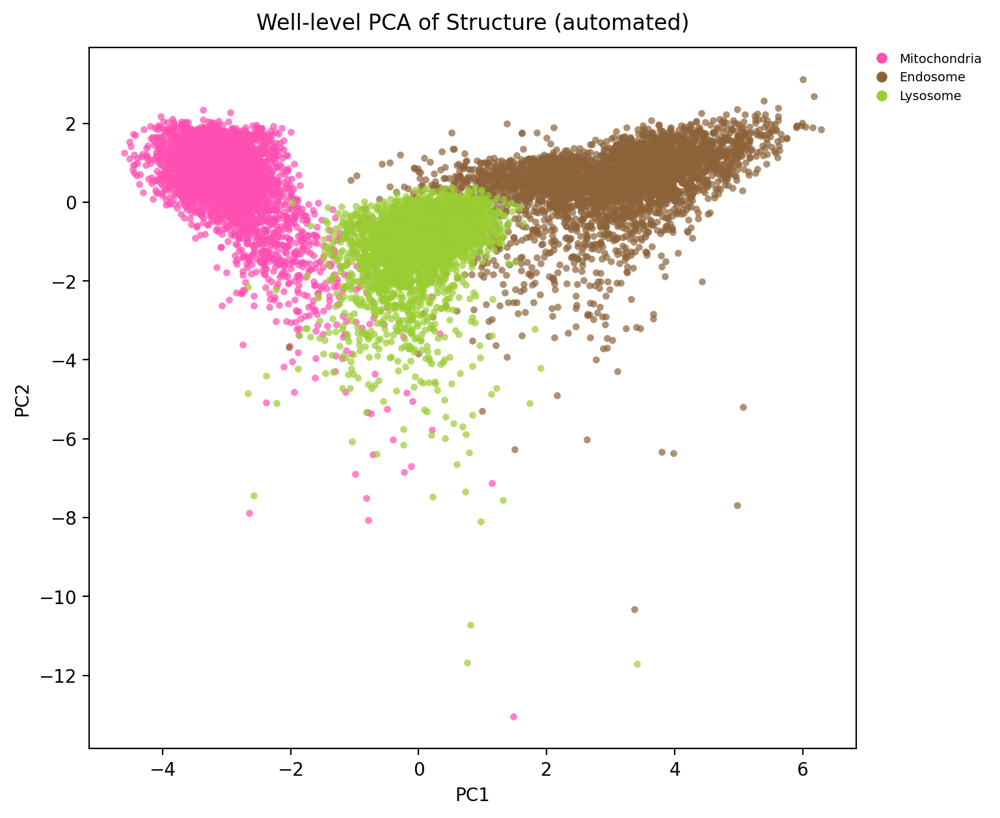

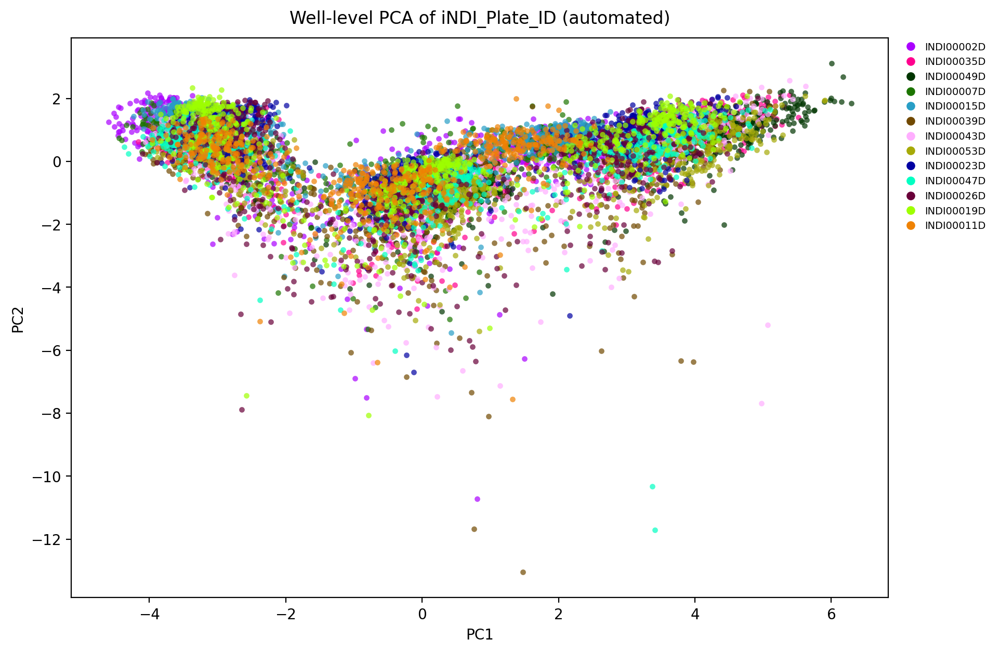

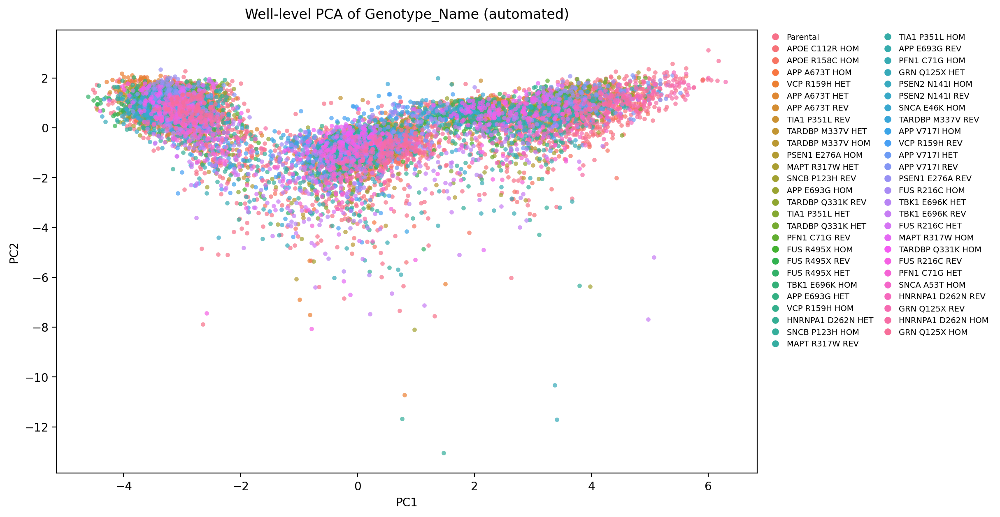

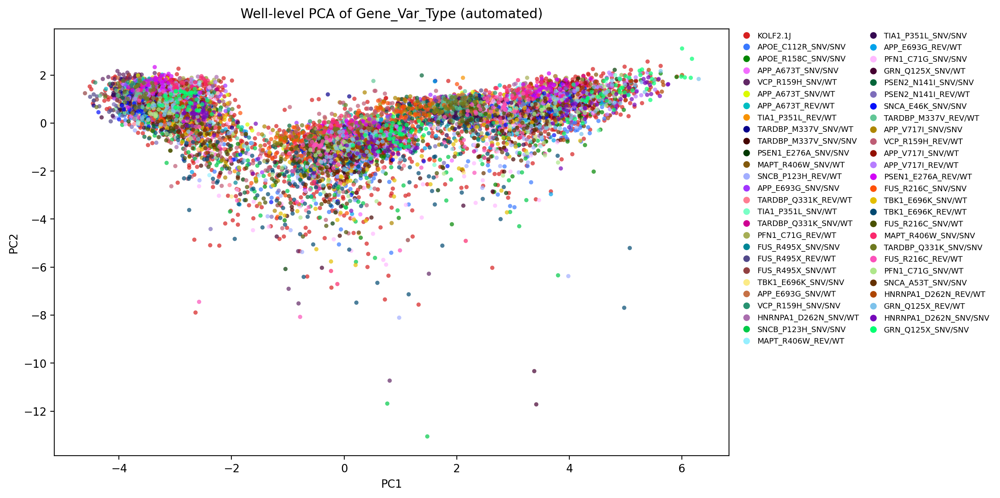

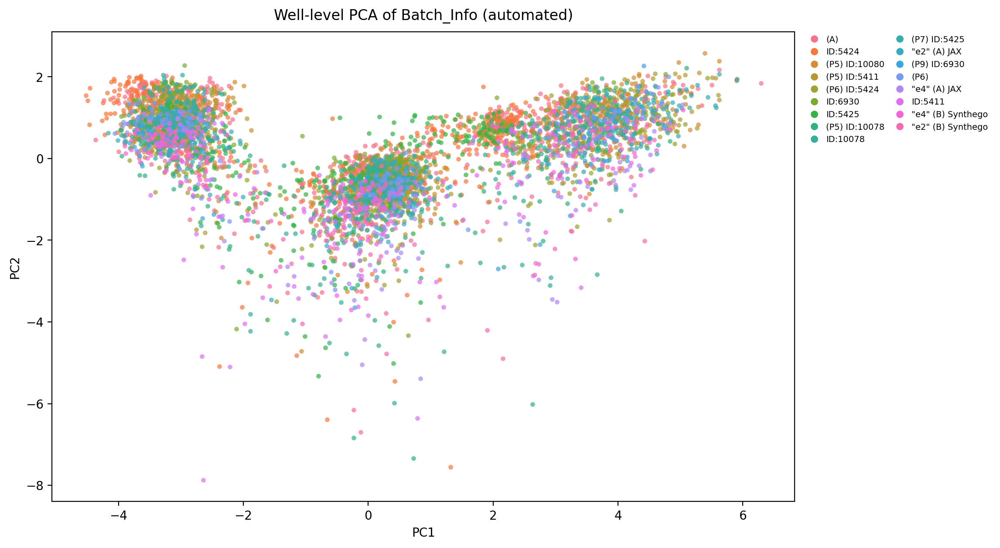

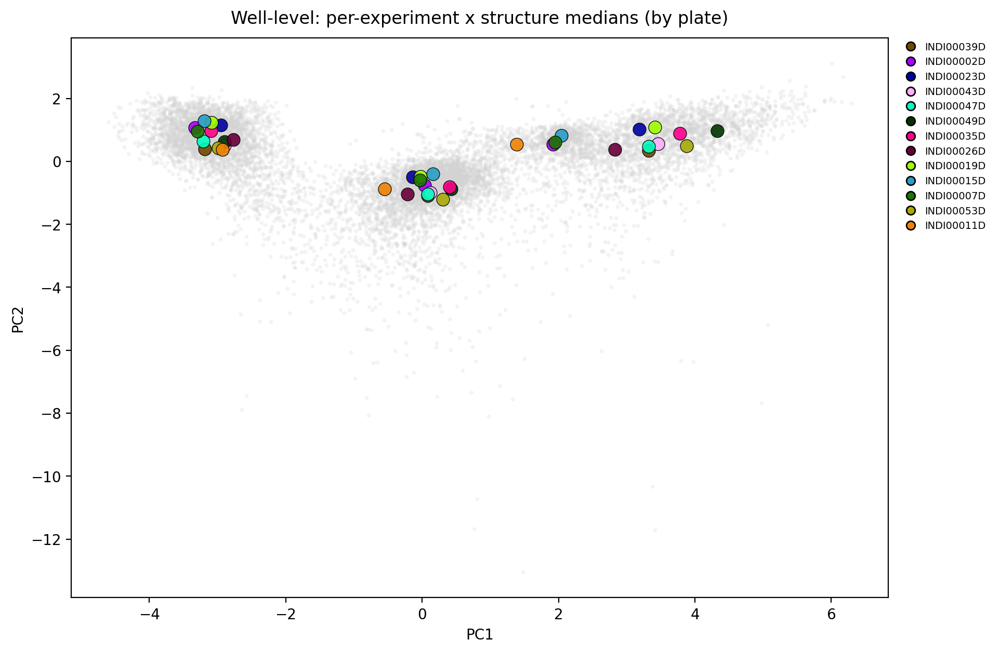

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ================================================================
# WELL-LEVEL aggregation on AUTOMATED data (median->image, mean->well)
# ================================================================
WELL_KEYS  = ["Measurement_ID", "subdirectory"]
IMAGE_KEY  = "DAPI_filename"
STRUCT_KEY = "Structure"

GROUP_KEYS = [STRUCT_KEY, *WELL_KEYS, IMAGE_KEY]
DROP_COLS  = set(FEATURES) | {f"PC{i+1}" for i in range(10)} | set(GROUP_KEYS) \
             | {"Nucleus_ID", "channel_filename"}
META_COLS  = [c for c in auto.columns if c not in DROP_COLS]

# safety: confirm metadata carried by .first() is invariant within a well
for col in ["Genotype_Name", "iNDI_Plate_ID", "prep_method"]:
    n_bad = (auto.groupby(WELL_KEYS)[col].nunique() > 1).sum()
    flag = "  <-- CHECK" if n_bad else ""
    print(f"{col}: {n_bad} well(s) with >1 value{flag}")

# --- stage 1: median across ROIs within each image (per structure) ---
agg_image = {**{f: "median" for f in FEATURES},
             **{m: "first" for m in META_COLS}}
image_level = auto.groupby(GROUP_KEYS, as_index=False).agg(agg_image)
print(f"\nImage-level: {len(image_level)} rows "
      f"({auto[IMAGE_KEY].nunique()} images x {auto[STRUCT_KEY].nunique()} structures)")

# --- stage 2: mean across images within each well (per structure) ---
WELL_GROUP = [STRUCT_KEY, *WELL_KEYS]
agg_well = {**{f: "mean" for f in FEATURES},
            **{m: "first" for m in META_COLS}}
well_level = image_level.groupby(WELL_GROUP, as_index=False).agg(agg_well)
print(f"Well-level: {len(well_level)} rows "
      f"({well_level.groupby(WELL_KEYS).ngroups} wells x structures)")

# ================================================================
# refit PCA on WELL-LEVEL automated profiles
# ================================================================
Xw_df = well_level[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = Xw_df.notna().all(axis=1)
well_level = well_level[keep].reset_index(drop=True)
Xw_df = Xw_df[keep].reset_index(drop=True)
print(f"\nWell-level PCA on {len(well_level)} rows (dropped {(~keep).sum()} NaN)")

scaler_well = StandardScaler()
Xw = scaler_well.fit_transform(Xw_df.values)
pca_well = PCA(n_components=len(FEATURES))
scores_w = pca_well.fit_transform(Xw)
for i in range(min(5, scores_w.shape[1])):
    well_level[f"PC{i+1}"] = scores_w[:, i]

evw = pca_well.explained_variance_ratio_
print("Well-level EVR:", evw[:5].round(3), "| cumulative:", np.cumsum(evw)[:5].round(3))

# ================================================================
# standard panels (larger markers — far fewer points now)
# ================================================================
well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(well_shuf, "Structure", palette=STRUCTURE_COLORS,
            s=15, alpha=0.7, figsize=(9, 7),
            title="Well-level PCA of Structure (automated)")
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_palette,
            s=15, alpha=0.7, figsize=(12, 7),
            title="Well-level PCA of iNDI_Plate_ID (automated)")
pca_scatter(well_shuf, "Genotype_Name",
            s=15, alpha=0.7, figsize=(13, 7), legend_ncol=2,
            title="Well-level PCA of Genotype_Name (automated)")
pca_scatter(well_shuf, "Gene_Var_Type",
            s=15, alpha=0.7, figsize=(13, 7), legend_ncol=2,
            title="Well-level PCA of Gene_Var_Type (automated)")
pca_scatter(well_shuf, "Batch_Info",
            s=15, alpha=0.7, figsize=(13, 7), legend_ncol=2,
            title="Well-level PCA of Batch_Info (automated)")

# ================================================================
# well-level centroids by plate (batch spread at well resolution)
# ================================================================
cent_well = centroid_overlay(
    well_level, color_col="iNDI_Plate_ID",
    group_keys=["Measurement_ID", "Structure"],
    palette=plate_palette, stat="median",
    bg_s=8, bg_alpha=0.25,          # only this call gets the heavier background
    s_centroid=80, figsize=(12, 7),
    title="Well-level: per-experiment x structure medians (by plate)",
)

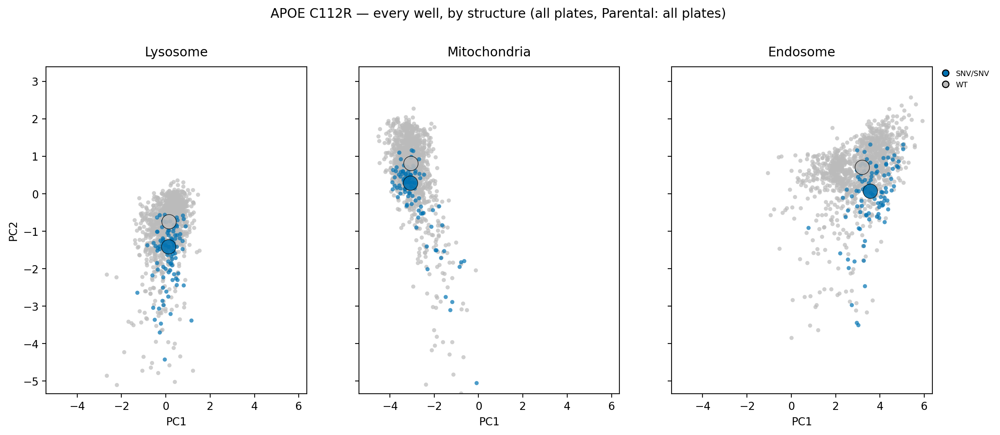

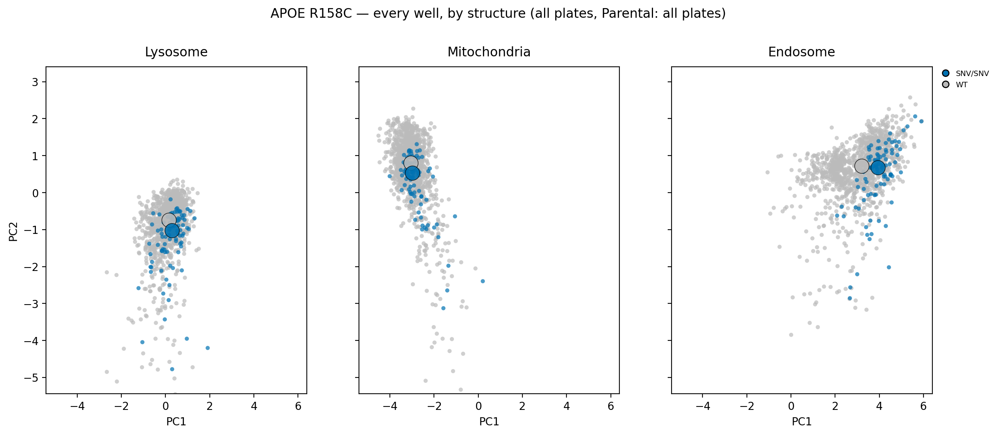

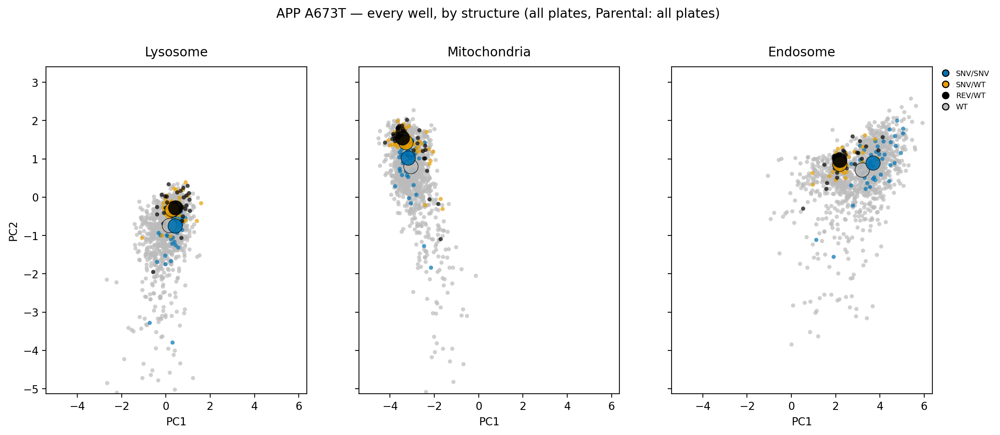

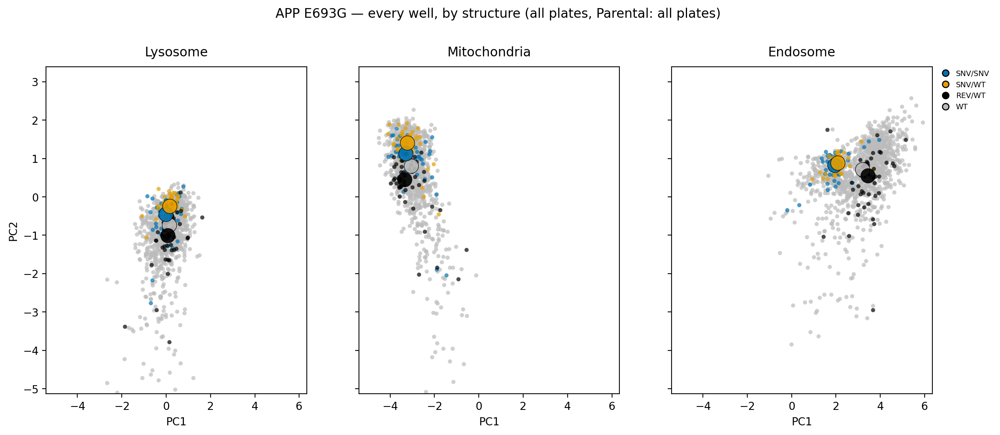

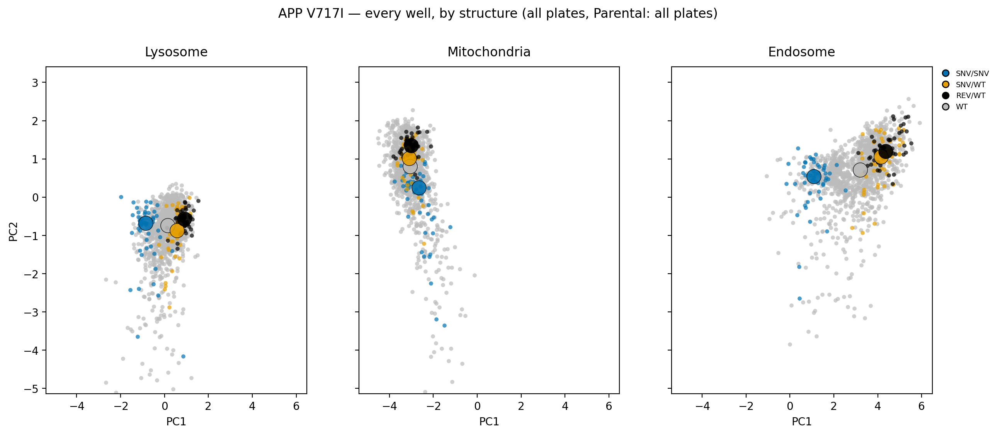

...

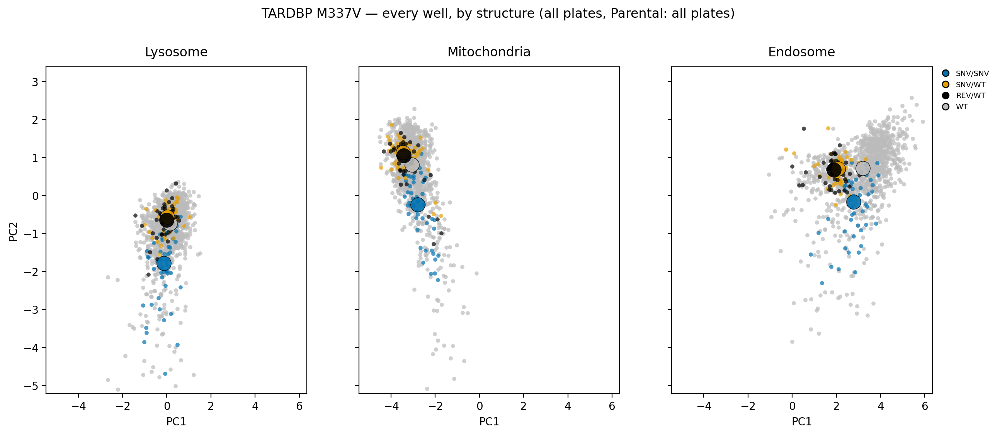

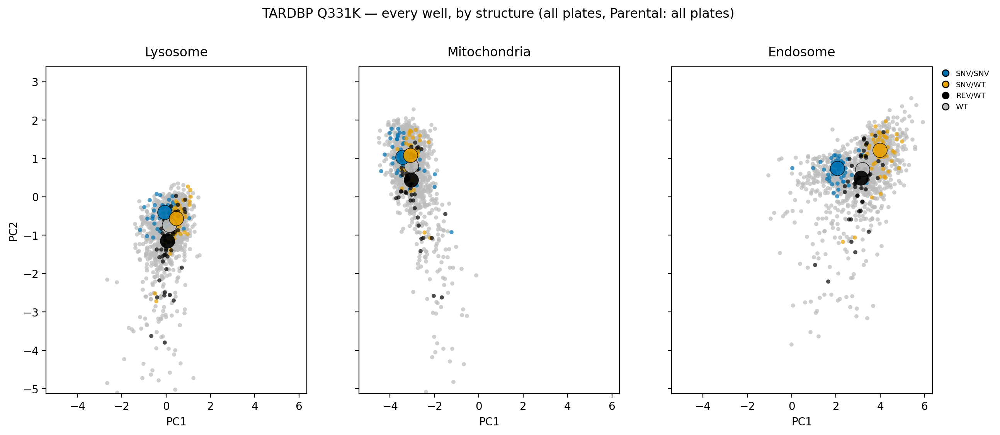

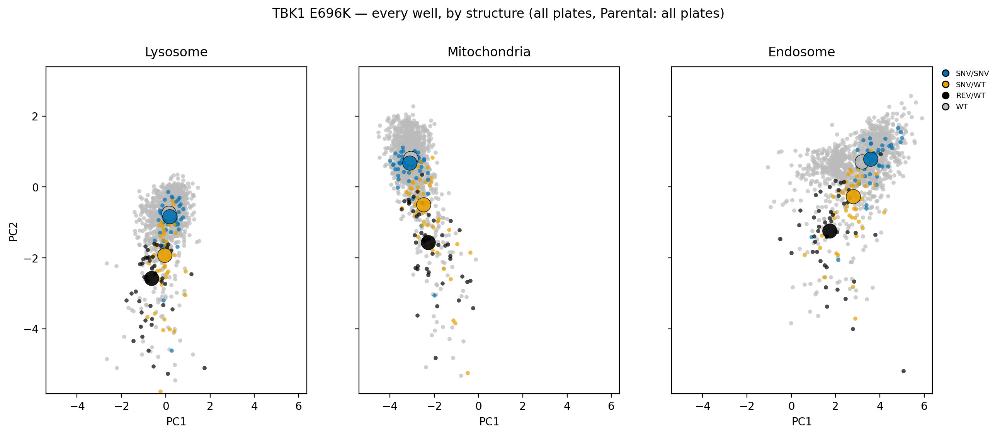

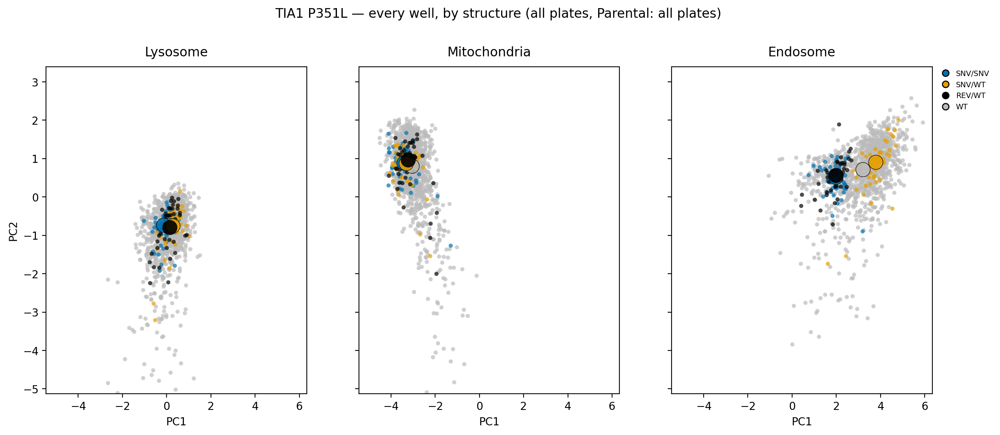

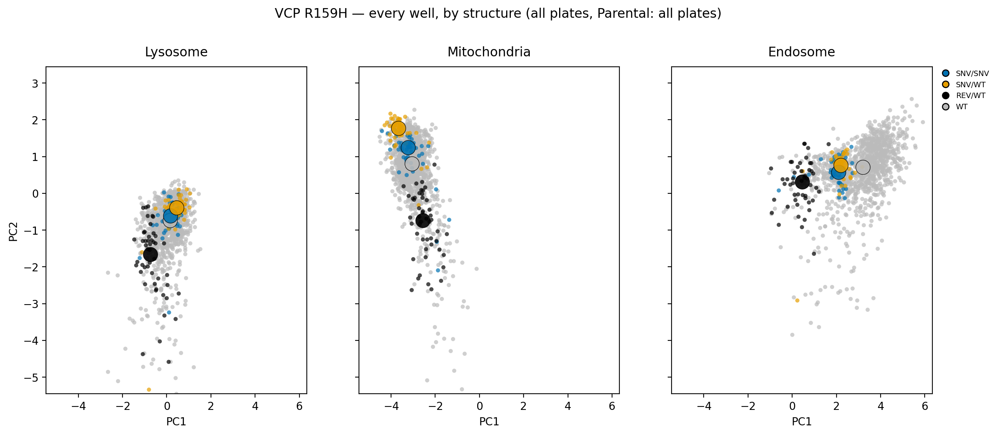

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# push this to the autonomous only section

# ==========================================================================
# Config
# ==========================================================================
WT_GENE = "KOLF2.1J"                       # Gene value marking Parental / WT
DEFAULT_STRUCTS = ["Lysosome", "Mitochondria", "Endosome"]

# colorblind-safe palette keyed by Genotype (Okabe-Ito; no red/green pair).
# Parental wells (Gene == WT_GENE) are colored as WT regardless of Genotype.
# /Y genotypes are hemizygous (X-linked genes, e.g. UBQLN2).
GENO_COLORS = {
    "WT":      "#BBBBBB",   # grey         (parental / KOLF2.1J background)
    "SNV/WT":  "#E69F00",   # orange       (heterozygous mutant)
    "SNV/SNV": "#0072B2",   # blue         (homozygous mutant)
    "REV/WT":  "#000000",   # black        (revertant)
    "SNV/Y":   "#009E73",   # green        (hemizygous mutant, X-linked)
    "REV/Y":   "#CC79A7",   # magenta/pink (hemizygous revertant, X-linked)
    "OTHER":   "#F0E442",   # yellow       (fallthrough)
}
GENO_ORDER = ["SNV/SNV", "SNV/WT", "SNV/Y", "REV/WT", "REV/Y", "WT"]  # legend / draw order

# color key column: Parental forced to "WT", everything else its Genotype value
def _color_key(df):
    is_wt = df["Gene"].astype(str).str.strip().str.upper() == WT_GENE.upper()
    return np.where(is_wt, "WT", df["Genotype"].astype(str).str.strip())


# ==========================================================================
# Figure: per-structure PCA facets for one allele
# ==========================================================================
def facet_variant_pca(
    df, gene, variant, pcx="PC1", pcy="PC2",
    structs=DEFAULT_STRUCTS, title=None, pad=1.5,
    parental=None, s=15, alpha=0.7, s_centroid=180, figsize=None,
):
    """Per-structure PCA facets for one (gene, variant), styled like pca_scatter.

    Reads existing PC columns straight from df (same space as the other
    well-level plots). Colors by the Genotype column; parental wells (passed in
    via `parental`) are colored WT.

    df       : well-level dataframe with PC columns attached.
    gene,    : the allele to plot (its wells pooled across all plates).
    variant  :
    parental : dataframe of parental wells to overlay (pooled across plates).
    """
    src = df[(df["Gene"] == gene) & (df["Variant"] == variant)].copy()
    if parental is not None and not parental.empty:
        src = pd.concat([src, parental], ignore_index=True)
    if src.empty:
        print(f"[skip] no rows for {gene} {variant}")
        return None

    src["_ckey"] = _color_key(src)

    # flag revertant-only / mutant-absent alleles so the figure is honest:
    # if no SNV/* genotype is present among the non-WT wells, there's no mutant
    # to compare against WT.
    nonwt = src.loc[src["_ckey"] != "WT", "_ckey"]
    has_mutant = nonwt.str.startswith("SNV").any()
    mutant_note = "" if has_mutant else "  [no mutant genotype — revertant only]"

    px, py = src[pcx].dropna(), src[pcy].dropna()
    if px.empty or py.empty:
        print(f"[skip] no finite PC values for {gene} {variant}")
        return None
    x_lo, x_hi = px.quantile(.01) - pad, px.quantile(.99) + pad
    y_lo, y_hi = py.quantile(.01) - pad, py.quantile(.99) + pad

    # every genotype actually present, ordered by GENO_ORDER with any
    # unrecognized values appended (so nothing is silently dropped).
    all_keys = list(pd.unique(src["_ckey"]))
    unknown = [k for k in all_keys if k not in GENO_COLORS]
    if unknown:
        print(f"[warning] {gene} {variant}: genotype(s) not in palette, "
              f"drawn as OTHER: {unknown}")
    keys_present = ([k for k in GENO_ORDER if k in all_keys]
                    + [k for k in all_keys
                       if k not in GENO_ORDER])   # unrecognized -> end
    # draw order: WT first (bottom), mutant genotypes on top. Legend keeps
    # the keys_present order (WT last among known).
    draw_order = ([k for k in keys_present if k == "WT"]
                  + [k for k in keys_present if k != "WT"])

    n = len(structs)
    if figsize is None:
        figsize = (5.2 * n, 5.5)
    fig, axes = plt.subplots(1, n, figsize=figsize, dpi=200,
                             sharex=True, sharey=True)
    if n == 1:
        axes = [axes]
    fig.subplots_adjust(right=0.86)   # room for the outside legend

    for ax, struct in zip(axes, structs):
        sub = src[src["Structure"] == struct]
        for k in draw_order:                        # clouds: WT first (bottom)
            gg = sub[sub["_ckey"] == k]
            ax.scatter(gg[pcx], gg[pcy], s=s, alpha=alpha,
                       color=GENO_COLORS.get(k, GENO_COLORS["OTHER"]),
                       linewidths=0, rasterized=True)
        for k in draw_order:                         # centroids: WT first too
            gg = sub[sub["_ckey"] == k]
            if gg.empty:
                continue
            ax.scatter(gg[pcx].median(), gg[pcy].median(), s=s_centroid,
                       color=GENO_COLORS.get(k, GENO_COLORS["OTHER"]),
                       edgecolor="k", linewidths=0.5, alpha=0.9, zorder=5)
        ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
        ax.set_title(struct, pad=10); ax.set_xlabel(pcx)

    axes[0].set_ylabel(pcy)

    handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=GENO_COLORS.get(k, GENO_COLORS["OTHER"]),
               markeredgecolor="k", label=k)
        for k in keys_present
    ]
    axes[-1].legend(handles=handles, loc="upper left",
                    bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=7,
                    borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8)

    fig.suptitle((title or f"{gene} {variant} — every well, by structure "
                  f"(all plates, Parental: all plates)") + mutant_note, y=1.02)
    plt.show()
    return fig


# ==========================================================================
# Driver: one figure per (gene, variant); wells pooled across all plates,
# Parental pooled across all plates as the shared reference.
# ==========================================================================
well_df = well_level

is_parental = well_df["Gene"].astype(str).str.strip().str.upper() == WT_GENE.upper()
parental_all = well_df[is_parental].copy()

variants = (well_df.loc[~is_parental, ["Gene", "Variant"]]
            .dropna().drop_duplicates().sort_values(["Gene", "Variant"]))

for gene, variant in variants.itertuples(index=False):
    facet_variant_pca(well_df, gene, variant, parental=parental_all)

Manual-only: 1199175 rows (1737032 Automated rows dropped, 59.2%)
  8 plates, 49 genotypes, 3 structures
PCA on 1199175 rows (dropped 0 NaN)
Manual-only EVR: [0.498 0.133 0.107 0.084 0.064] | cumulative: [0.498 0.631 0.739 0.823 0.888]


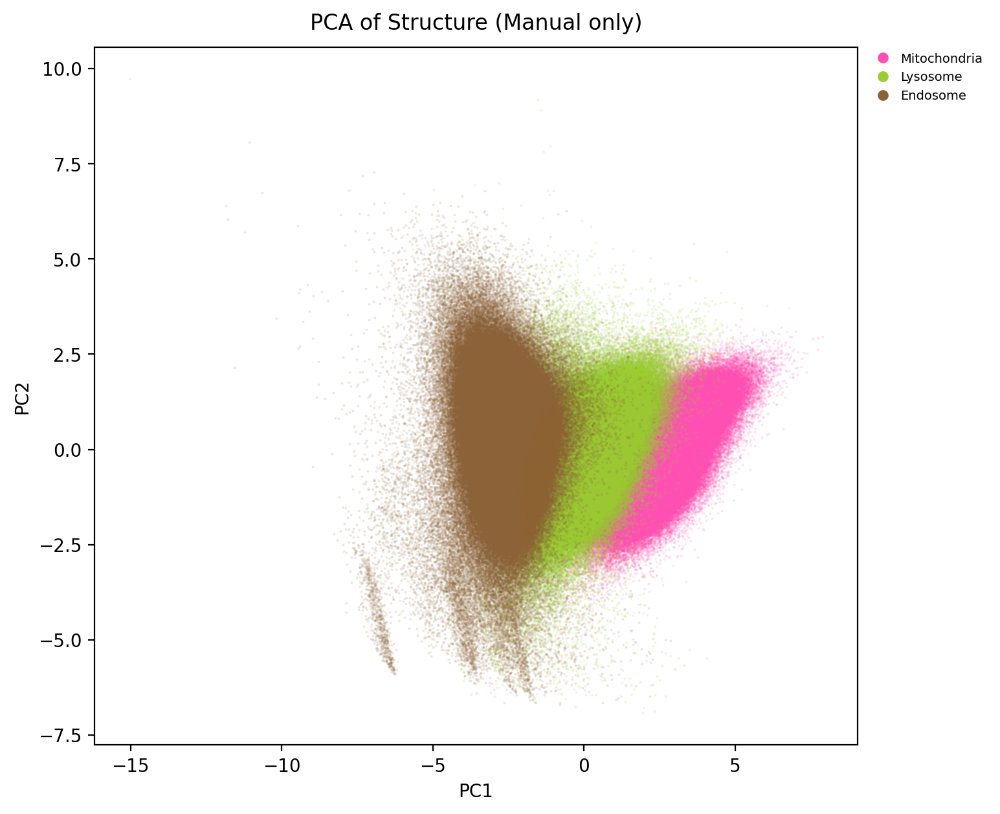

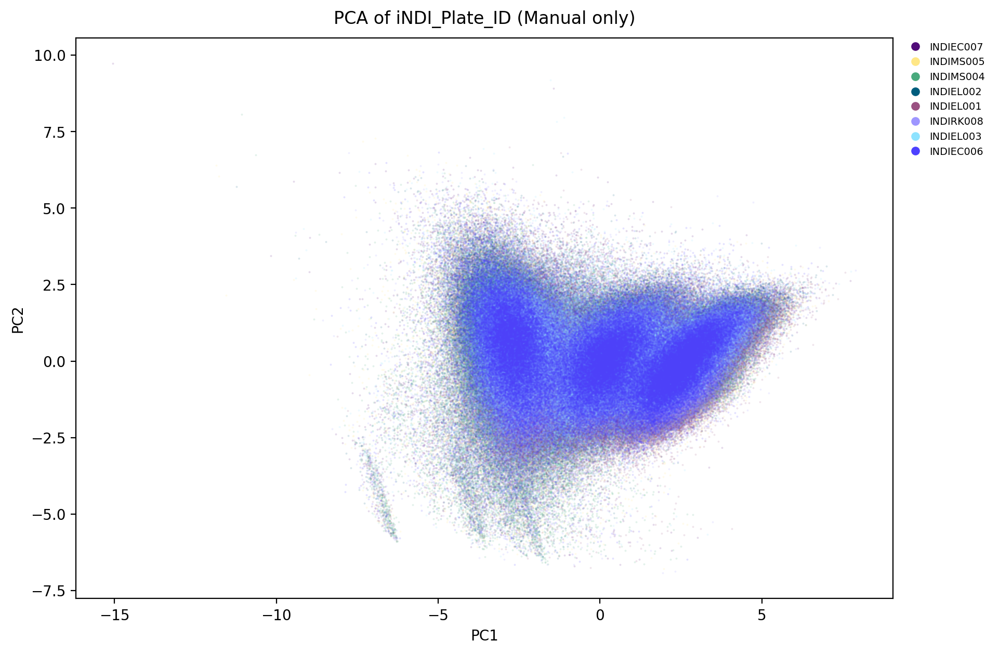

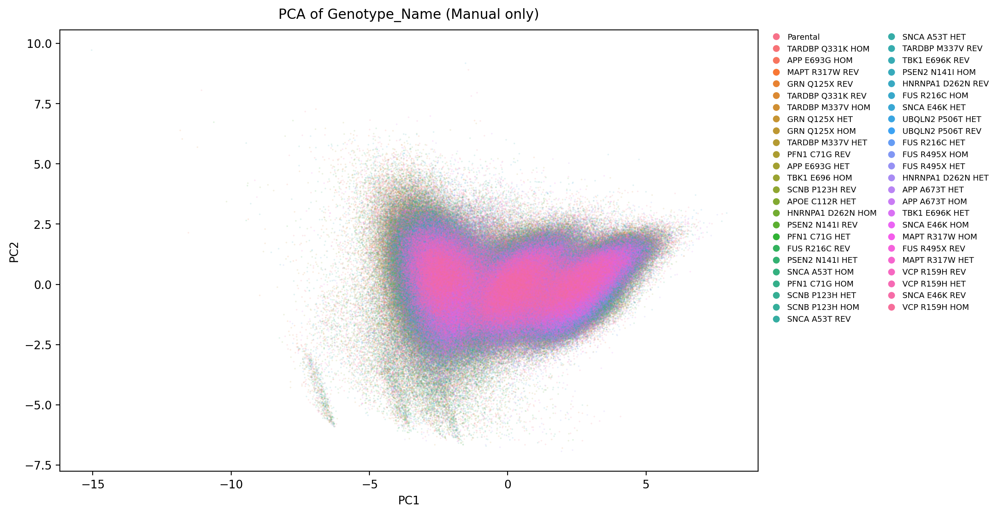

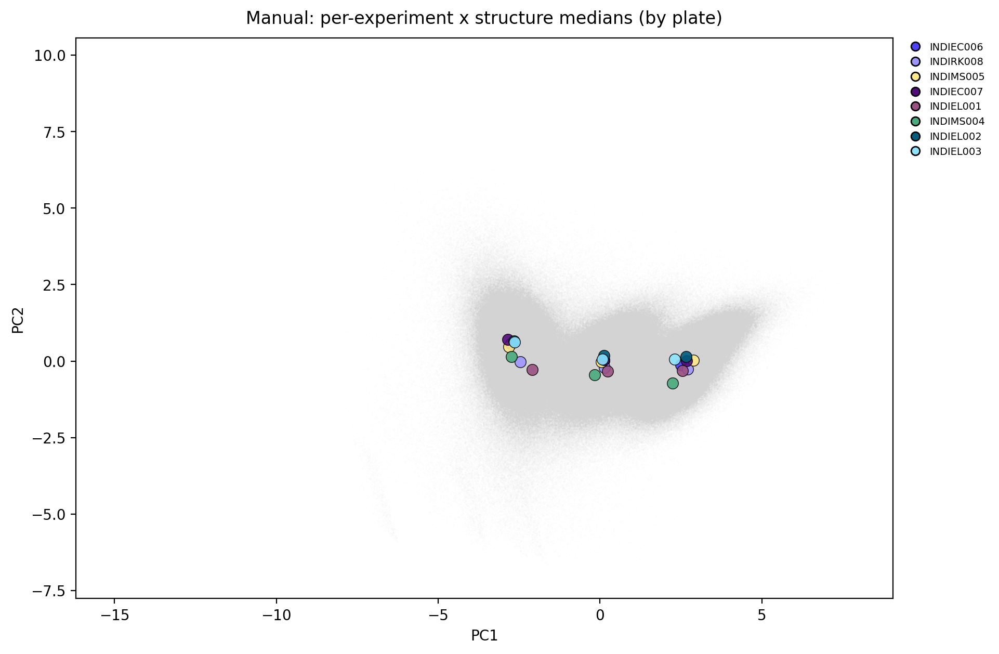

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# --- subset to manual prep only ---
manual = df[df["prep_method"] == "manual"].copy()
print(f"Manual-only: {len(manual)} rows "
      f"({len(df) - len(manual)} Automated rows dropped, "
      f"{(len(df)-len(manual))/len(df)*100:.1f}%)")
print(f"  {manual['iNDI_Plate_ID'].nunique()} plates, "
      f"{manual['Genotype_Name'].nunique()} genotypes, "
      f"{manual['Structure'].nunique()} structures")

# --- refit PCA on automated data only (don't reuse the pooled fit) ---
X_df = manual[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = X_df.notna().all(axis=1)
manual = manual[keep].reset_index(drop=True)
X_df = X_df[keep].reset_index(drop=True)
print(f"PCA on {len(manual)} rows (dropped {(~keep).sum()} NaN)")

scaler_manual = StandardScaler()
X = scaler_manual.fit_transform(X_df.values)
pca_manual = PCA(n_components=len(FEATURES))
scores = pca_manual.fit_transform(X)
for i in range(scores.shape[1]): 
    manual[f"PC{i+1}"] = scores[:, i]

ev = pca_manual.explained_variance_ratio_
print("Manual-only EVR:", ev[:5].round(3), "| cumulative:", np.cumsum(ev)[:5].round(3))

# --- standard panels ---
manual_shuf = manual.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(manual_shuf, "Structure", palette=STRUCTURE_COLORS,
            figsize=(9, 7), title="PCA of Structure (Manual only)")
pca_scatter(manual_shuf, "iNDI_Plate_ID", palette=plate_palette,
            figsize=(12, 7), title="PCA of iNDI_Plate_ID (Manual only)")
pca_scatter(manual_shuf, "Genotype_Name",
            figsize=(13, 7), legend_ncol=2, title="PCA of Genotype_Name (Manual only)")

# --- per-experiment x structure median centroids, colored by plate ---
# batch spread within the manual cohort
cent_manual = centroid_overlay(
    manual, color_col="iNDI_Plate_ID",
    group_keys=["Measurement_ID", "Structure"],
    palette=plate_palette, stat="median", bg_frac=1.0,
    title="Manual: per-experiment x structure medians (by plate)",
    figsize=(12, 7),
)

Genotype_Name: 0 well(s) with >1 value
iNDI_Plate_ID: 0 well(s) with >1 value
prep_method: 0 well(s) with >1 value

Image-level: 223968 rows (11755 images x 3 structures)
Well-level: 6583 rows (2197 wells x structures)

Well-level PCA on 6583 rows (dropped 0 NaN)
Well-level EVR: [0.677 0.137 0.091 0.037 0.031] | cumulative: [0.677 0.815 0.906 0.943 0.974]


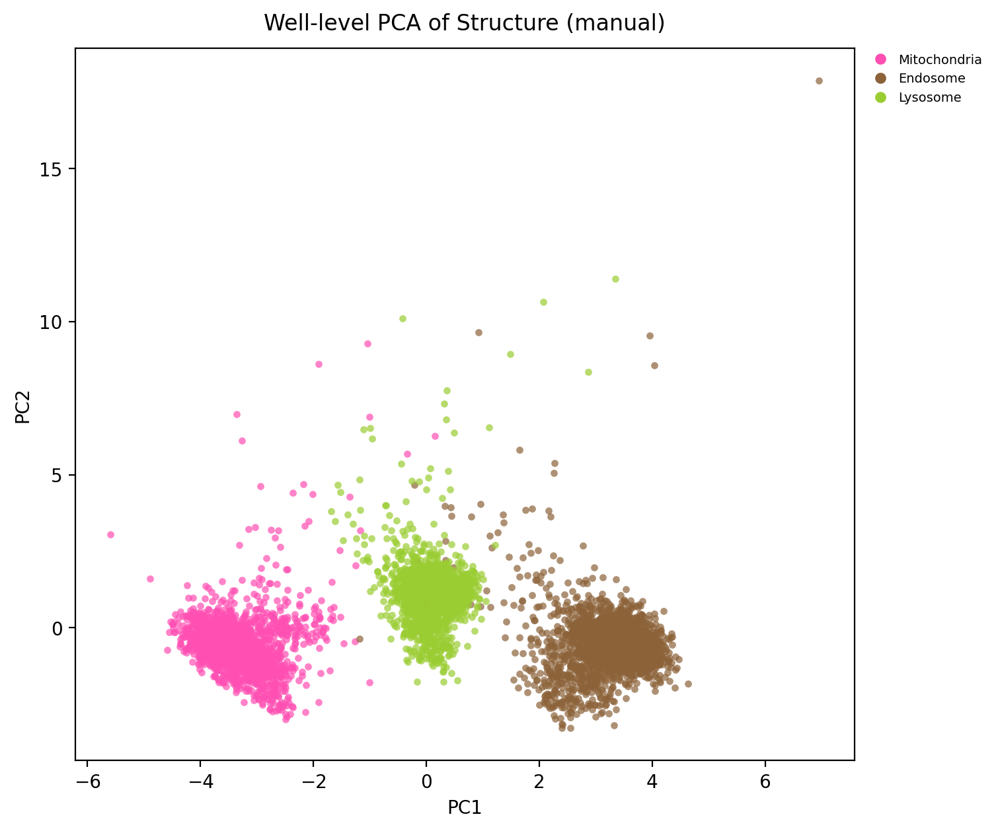

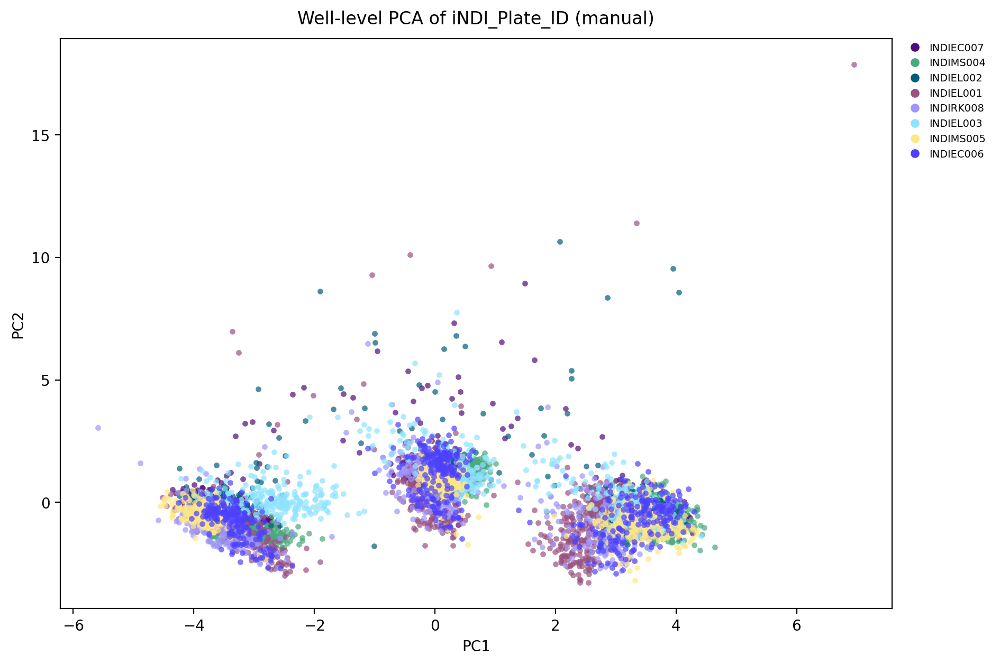

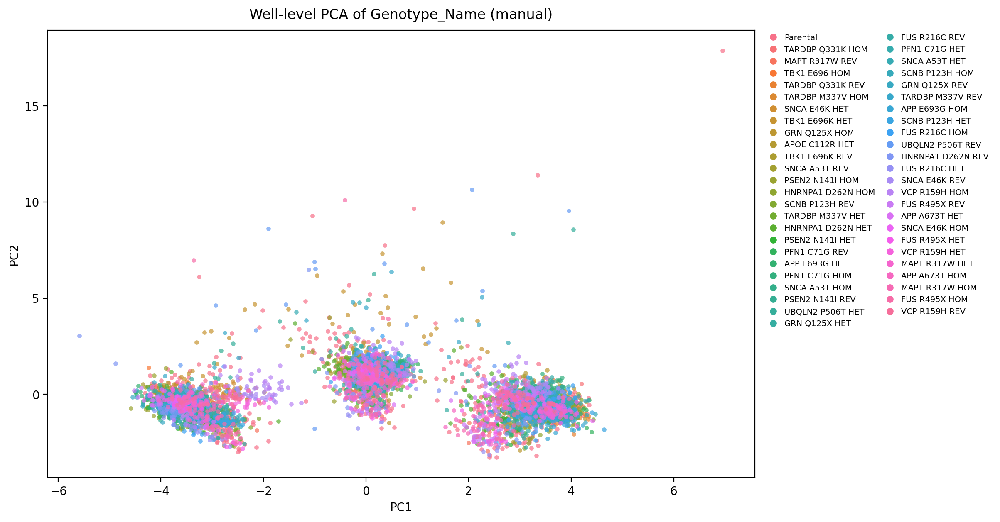

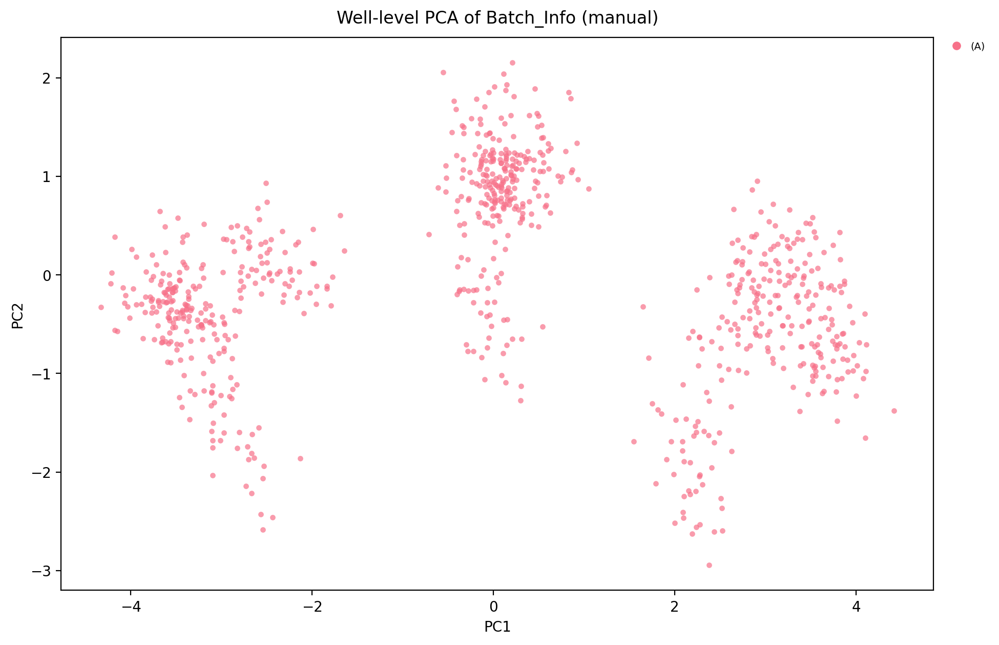

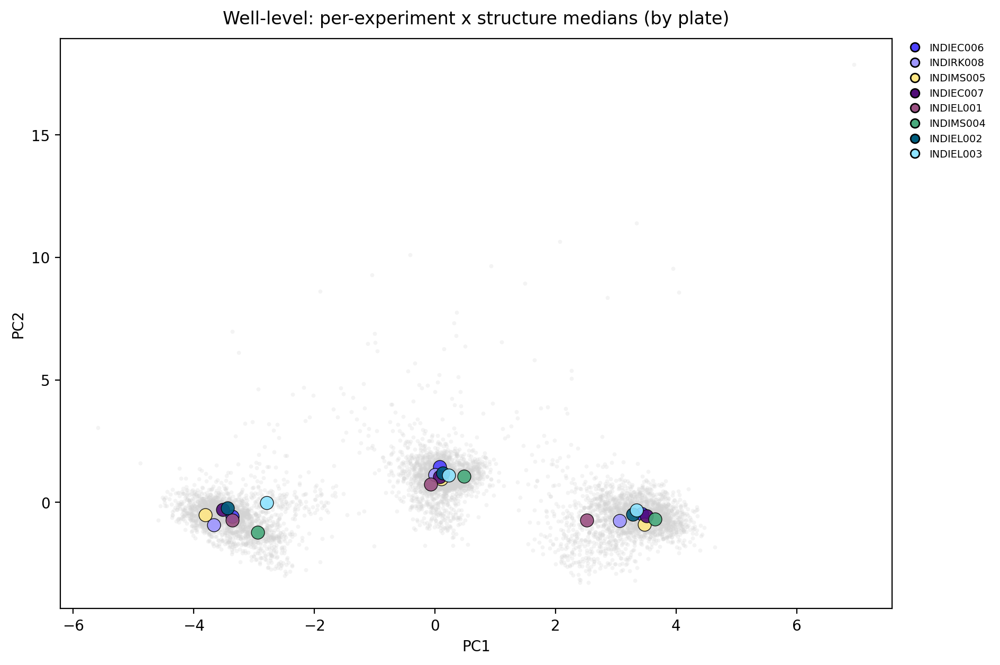

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ================================================================
# WELL-LEVEL aggregation on MANUAL data (median->image, mean->well)
# ================================================================
WELL_KEYS  = ["Measurement_ID", "subdirectory"]
IMAGE_KEY  = "DAPI_filename"
STRUCT_KEY = "Structure"

GROUP_KEYS = [STRUCT_KEY, *WELL_KEYS, IMAGE_KEY]
DROP_COLS  = set(FEATURES) | {f"PC{i+1}" for i in range(10)} | set(GROUP_KEYS) \
             | {"Nucleus_ID", "channel_filename"}
META_COLS  = [c for c in manual.columns if c not in DROP_COLS]

# safety: confirm metadata carried by .first() is invariant within a well
for col in ["Genotype_Name", "iNDI_Plate_ID", "prep_method"]:
    n_bad = (manual.groupby(WELL_KEYS)[col].nunique() > 1).sum()
    flag = "  <-- CHECK" if n_bad else ""
    print(f"{col}: {n_bad} well(s) with >1 value{flag}")

# --- stage 1: median across ROIs within each image (per structure) ---
agg_image = {**{f: "median" for f in FEATURES},
             **{m: "first" for m in META_COLS}}
image_level = manual.groupby(GROUP_KEYS, as_index=False).agg(agg_image)
print(f"\nImage-level: {len(image_level)} rows "
      f"({manual[IMAGE_KEY].nunique()} images x {manual[STRUCT_KEY].nunique()} structures)")

# --- stage 2: mean across images within each well (per structure) ---
WELL_GROUP = [STRUCT_KEY, *WELL_KEYS]
agg_well = {**{f: "mean" for f in FEATURES},
            **{m: "first" for m in META_COLS}}
well_level = image_level.groupby(WELL_GROUP, as_index=False).agg(agg_well)
print(f"Well-level: {len(well_level)} rows "
      f"({well_level.groupby(WELL_KEYS).ngroups} wells x structures)")

# ================================================================
# refit PCA on WELL-LEVEL manual profiles
# ================================================================
Xw_df = well_level[FEATURES].replace([np.inf, -np.inf], np.nan)
keep = Xw_df.notna().all(axis=1)
well_level = well_level[keep].reset_index(drop=True)
Xw_df = Xw_df[keep].reset_index(drop=True)
print(f"\nWell-level PCA on {len(well_level)} rows (dropped {(~keep).sum()} NaN)")

scaler_well = StandardScaler()
Xw = scaler_well.fit_transform(Xw_df.values)
pca_well = PCA(n_components=len(FEATURES))
scores_w = pca_well.fit_transform(Xw)
for i in range(min(5, scores_w.shape[1])):
    well_level[f"PC{i+1}"] = scores_w[:, i]

evw = pca_well.explained_variance_ratio_
print("Well-level EVR:", evw[:5].round(3), "| cumulative:", np.cumsum(evw)[:5].round(3))

# ================================================================
# standard panels (larger markers — far fewer points now)
# ================================================================
well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
pca_scatter(well_shuf, "Structure", palette=STRUCTURE_COLORS,
            s=15, alpha=0.7, figsize=(9, 7),
            title="Well-level PCA of Structure (manual)")
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_palette,
            s=15, alpha=0.7, figsize=(12, 7),
            title="Well-level PCA of iNDI_Plate_ID (manual)")
pca_scatter(well_shuf, "Genotype_Name",
            s=15, alpha=0.7, figsize=(13, 7), legend_ncol=2,
            title="Well-level PCA of Genotype_Name (manual)")
pca_scatter(well_shuf, "Batch_Info",
            s=15, alpha=0.7, figsize=(13, 7), legend_ncol=2,
            title="Well-level PCA of Batch_Info (manual)")

# ================================================================
# well-level centroids by plate (batch spread at well resolution)
# ================================================================
cent_well = centroid_overlay(
    well_level, color_col="iNDI_Plate_ID",
    group_keys=["Measurement_ID", "Structure"],
    palette=plate_palette, stat="median",
    bg_s=8, bg_alpha=0.25,          # only this call gets the heavier background
    s_centroid=80, figsize=(12, 7),
    title="Well-level: per-experiment x structure medians (by plate)",
)

In [ ]:
src = pd.concat([
    well_level[(well_level.Gene=="PSEN2") & (well_level.Variant=="N141I")],
    parental_all,
], ignore_index=True)
print(pd.Series(_color_key(src)).value_counts(dropna=False))

WT      3425
None     378
Name: count, dtype: int64


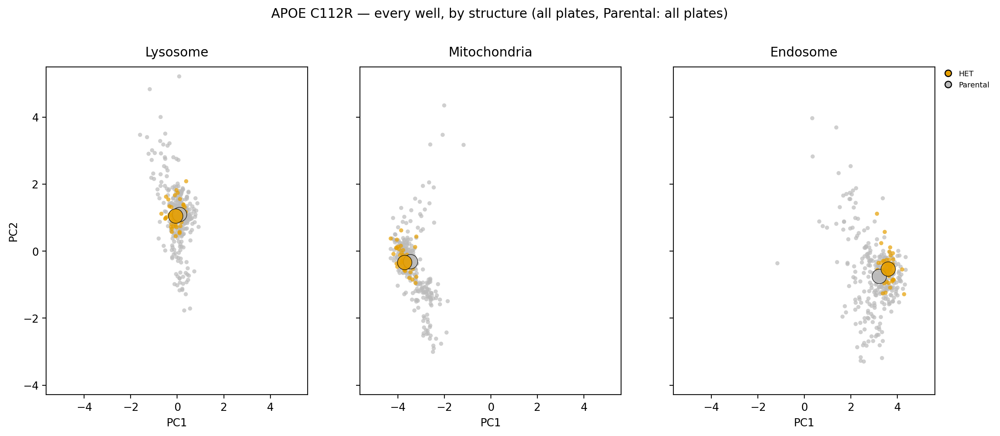

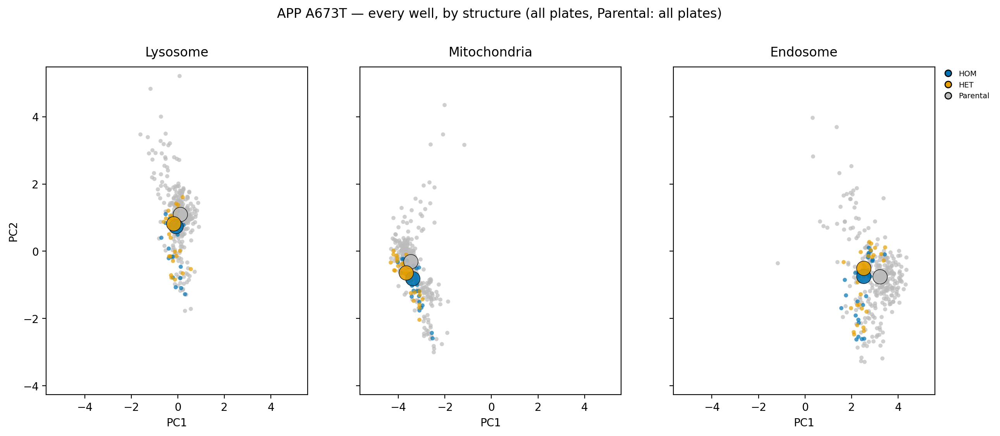

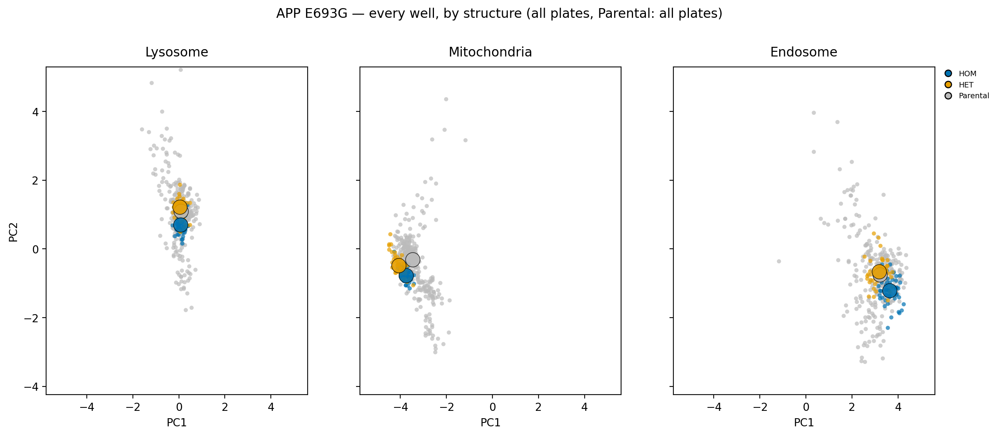

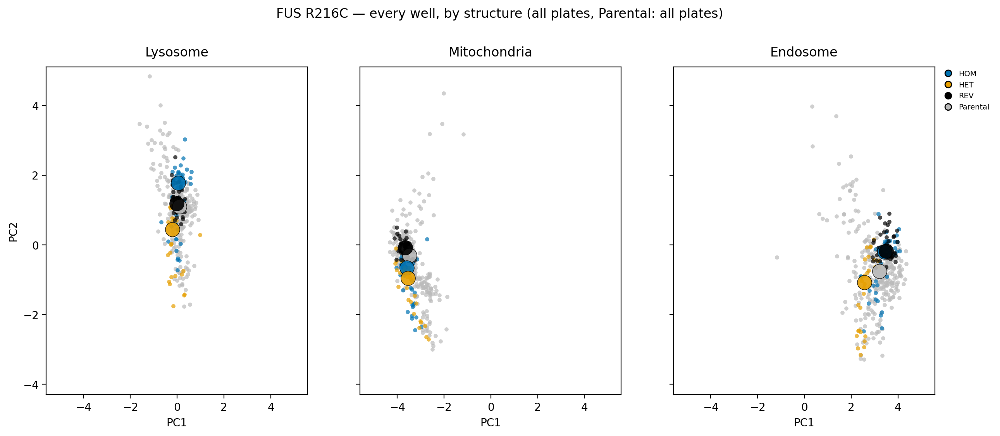

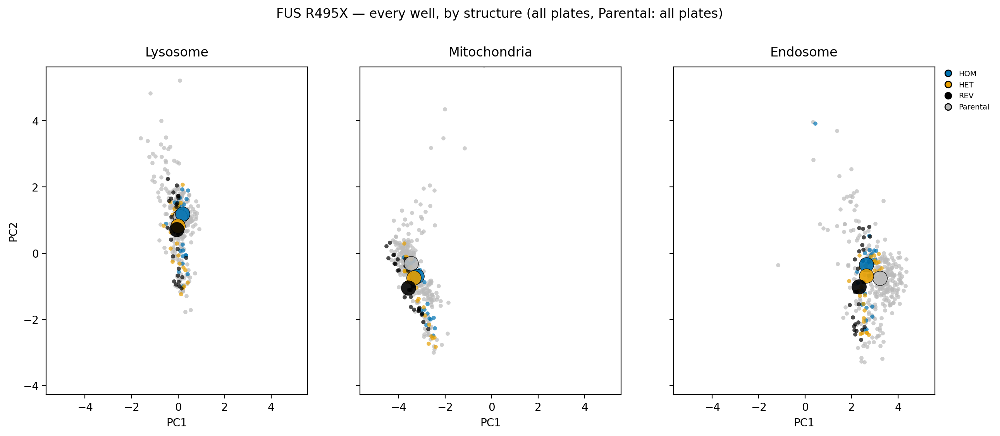

...

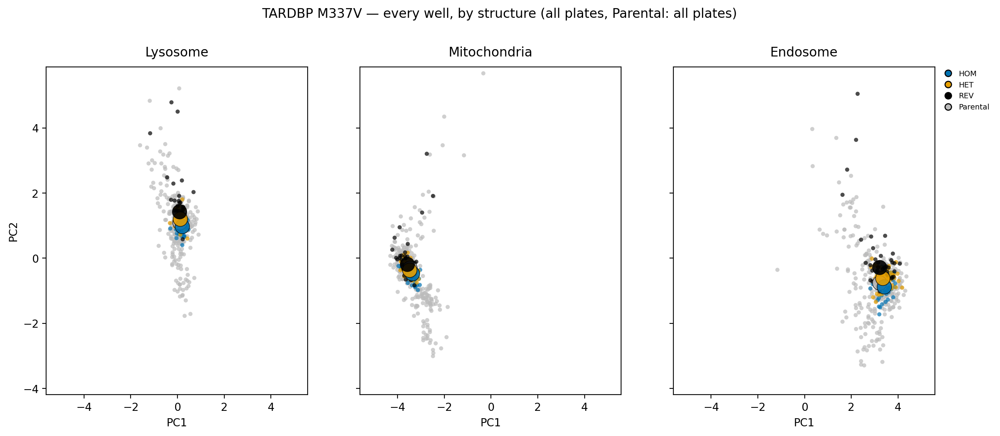

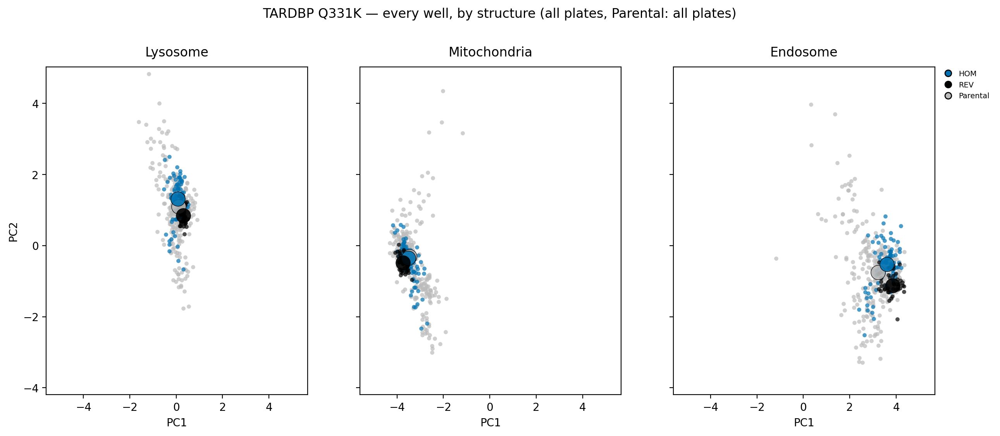

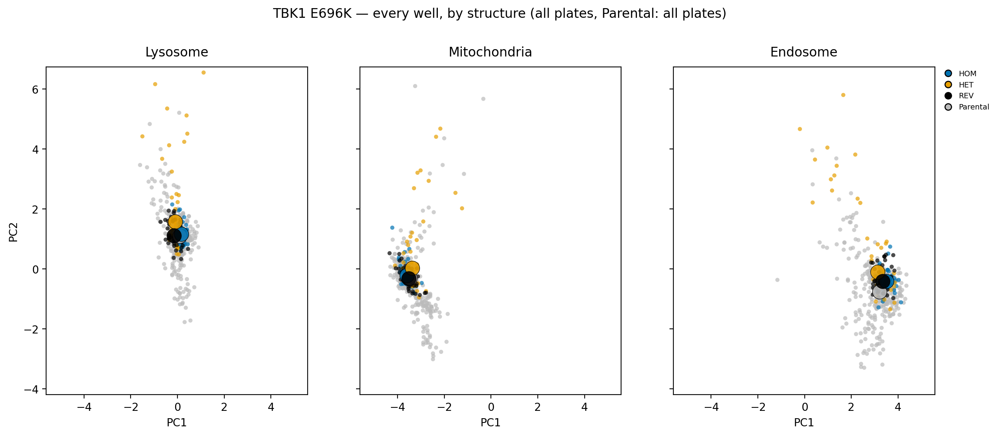

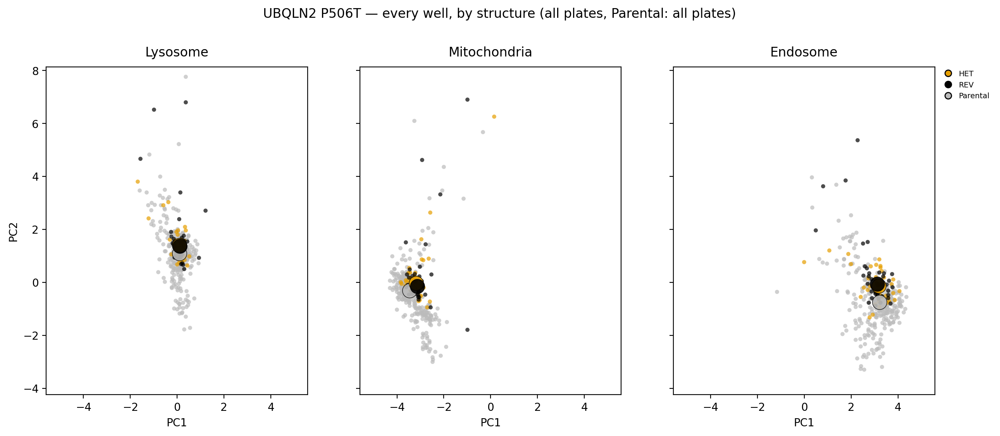

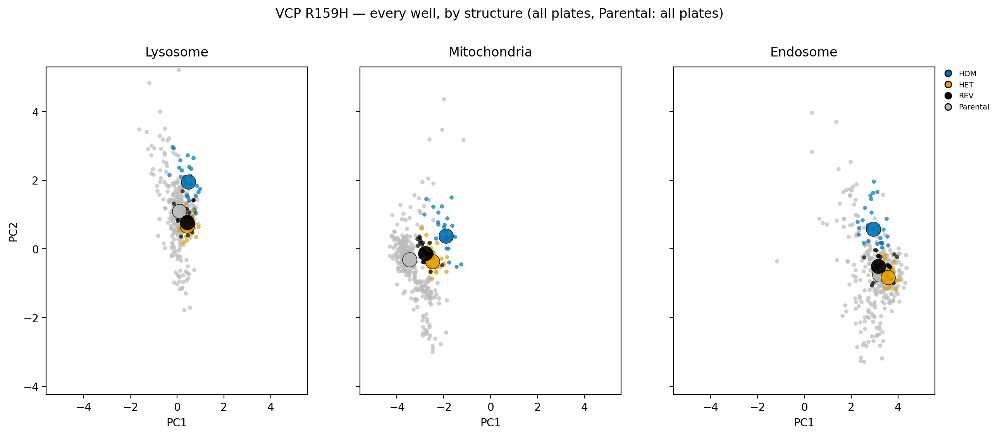

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==========================================================================
# Config
# ==========================================================================
PARENTAL_NAME = "Parental"                 # Genotype_Name value marking parental / WT
DEFAULT_STRUCTS = ["Lysosome", "Mitochondria", "Endosome"]

GENO_COLORS = {
    "Parental":"#BBBBBB",   # grey         (parental background)
    "HET":     "#E69F00",   # orange       (heterozygous mutant)
    "HOM":     "#0072B2",   # blue         (homozygous mutant)
    "REV":     "#000000",   # black        (revertant)
    "OTHER":   "#F0E442",   # yellow       (fallthrough)
}
GENO_ORDER = ["HOM", "HET", "REV", "Parental"]  # legend / draw order

# color key: parental -> "Parental"; otherwise the trailing zygosity token of
# Genotype_Name, e.g. "PSEN2 N141I HOM" -> "HOM". Upper-cased so mixed-case
# tokens still match the palette.
def _color_key(df):
    name = df["Genotype_Name"].astype(str).str.strip()
    is_parental = name.str.upper() == PARENTAL_NAME.upper()
    zygosity = name.str.split().str[-1].str.upper()   # HOM / HET / REV
    return np.where(is_parental, "Parental", zygosity)


# ==========================================================================
# Figure: per-structure PCA facets for one allele
# ==========================================================================
def facet_variant_pca(
    df, gene, variant, pcx="PC1", pcy="PC2",
    structs=DEFAULT_STRUCTS, title=None, pad=1.5,
    parental=None, s=15, alpha=0.7, s_centroid=180, figsize=None,
):
    """Per-structure PCA facets for one (gene, variant), styled like pca_scatter.

    Reads existing PC columns straight from df (same space as the other
    well-level plots). Colors by Genotype_Name (parental -> Parental, else the
    trailing HOM/HET/REV token); parental wells are passed in via `parental`.

    df       : well-level dataframe with PC columns attached.
    gene,    : the allele to plot (its wells pooled across all plates).
    variant  :
    parental : dataframe of parental wells to overlay (pooled across plates).
    """
    src = df[(df["Gene"] == gene) & (df["Variant"] == variant)].copy()
    if parental is not None and not parental.empty:
        src = pd.concat([src, parental], ignore_index=True)
    if src.empty:
        print(f"[skip] no rows for {gene} {variant}")
        return None

    src["_ckey"] = _color_key(src)

    # flag revertant-only / mutant-absent alleles so the figure is honest:
    # a mutant is any non-parental HOM/HET well. Without one there's nothing
    # to compare against parental.
    nonpar = src.loc[src["_ckey"] != "Parental", "_ckey"]
    has_mutant = nonpar.isin(["HOM", "HET"]).any()
    mutant_note = "" if has_mutant else "  [no mutant genotype — revertant only]"

    px, py = src[pcx].dropna(), src[pcy].dropna()
    if px.empty or py.empty:
        print(f"[skip] no finite PC values for {gene} {variant}")
        return None
    x_lo, x_hi = px.quantile(.01) - pad, px.quantile(.99) + pad
    y_lo, y_hi = py.quantile(.01) - pad, py.quantile(.99) + pad

    # every genotype actually present, ordered by GENO_ORDER with any
    # unrecognized values appended (so nothing is silently dropped).
    all_keys = list(pd.unique(src["_ckey"]))
    unknown = [k for k in all_keys if k not in GENO_COLORS]
    if unknown:
        print(f"[warning] {gene} {variant}: genotype(s) not in palette, "
              f"drawn as OTHER: {unknown}")
    keys_present = ([k for k in GENO_ORDER if k in all_keys]
                    + [k for k in all_keys
                       if k not in GENO_ORDER])   # unrecognized -> end
    # draw order: Parental first (bottom), mutant genotypes on top. Legend
    # keeps the keys_present order (Parental last among known).
    draw_order = ([k for k in keys_present if k == "Parental"]
                  + [k for k in keys_present if k != "Parental"])

    n = len(structs)
    if figsize is None:
        figsize = (5.2 * n, 5.5)
    fig, axes = plt.subplots(1, n, figsize=figsize, dpi=200,
                             sharex=True, sharey=True)
    if n == 1:
        axes = [axes]
    fig.subplots_adjust(right=0.86)   # room for the outside legend

    for ax, struct in zip(axes, structs):
        sub = src[src["Structure"] == struct]
        for k in draw_order:                        # clouds: Parental first (bottom)
            gg = sub[sub["_ckey"] == k]
            ax.scatter(gg[pcx], gg[pcy], s=s, alpha=alpha,
                       color=GENO_COLORS.get(k, GENO_COLORS["OTHER"]),
                       linewidths=0, rasterized=True)
        for k in draw_order:                         # centroids: Parental first too
            gg = sub[sub["_ckey"] == k]
            if gg.empty:
                continue
            ax.scatter(gg[pcx].median(), gg[pcy].median(), s=s_centroid,
                       color=GENO_COLORS.get(k, GENO_COLORS["OTHER"]),
                       edgecolor="k", linewidths=0.5, alpha=0.9, zorder=5)
        ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
        ax.set_title(struct, pad=10); ax.set_xlabel(pcx)

    axes[0].set_ylabel(pcy)

    handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=GENO_COLORS.get(k, GENO_COLORS["OTHER"]),
               markeredgecolor="k", label=k)
        for k in keys_present
    ]
    axes[-1].legend(handles=handles, loc="upper left",
                    bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=7,
                    borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8)

    fig.suptitle((title or f"{gene} {variant} — every well, by structure "
                  f"(all plates, Parental: all plates)") + mutant_note, y=1.02)
    plt.show()
    return fig


# ==========================================================================
# Driver: one figure per (gene, variant); wells pooled across all plates,
# Parental pooled across all plates as the shared reference.
# ==========================================================================
well_df = well_level

well_df.loc[
    well_df["Genotype_Name"].str.strip() == "TBK1 E696K HOM",
    "Variant",
] = "E696K"

is_parental = well_df["Genotype_Name"].astype(str).str.strip().str.upper() == PARENTAL_NAME.upper()
parental_all = well_df[is_parental].copy()

variants = (well_df.loc[~is_parental, ["Gene", "Variant"]]
            .dropna().drop_duplicates().sort_values(["Gene", "Variant"]))

for gene, variant in variants.itertuples(index=False):
    facet_variant_pca(well_df, gene, variant, parental=parental_all)